# SINASC 2014–2024 — contrato metodológico da V2 e diagnóstico pré-estimação (09d)

> **Etapa de congelamento e viabilidade.** Nenhum efeito de B ou C é estimado, nenhum modelo de desfecho é ajustado e nenhum AIPW é calculado. A V1 permanece intacta.

> **Resumo.**
> 1. **Decisão congelada antes de qualquer ajuste** (contrato gravado em 2026-10-01 13:39:46, sem nenhum checkpoint existente): **B (1–3 vs 4–6) é a V2 principal**, **C (1–3 vs 4–5) é a sensibilidade estrutural**, **A (1–3 vs 4–9) permanece como V1 histórica** e **D (*landmark*) fica pendente**. A justificativa vem do 09c, da literatura e dos contratos — nenhum efeito de B ou C foi observado.
> 2. B reduz a fração de nascimentos estruturalmente impedidos de pertencer ao controle de 1,35% para 0,007% (L1) e retém 86,8% dos controles da V1; C leva essa fração a praticamente zero, mas exclui 672.861 controles a mais.
> 3. **Propensity diagnóstico** (logística L2, `C=1`, sete X, 5 partições por T, seed 20240925): 110 ajustes novos (B e C × 11 anos × 5 partições), todos convergidos. O código novo reproduz o OOF certificado do notebook 08 para A com diferença máxima **0,0** (2014 e 2024).
> 4. **B:** ESS/N dos controles 0,664–0,749 e dos tratados ≥ 0,982; maior |SMD| ponderado 0,016–0,024 (bruto 0,37–0,44); nenhum escore fora de [0,01; 0,99]; fora de [0,05; 0,95] entre 6,2% e 10,6%. **10 anos `APROVADO`, 2024 `SINALIZADO` (caudas 10,56% > 10%), nenhum `BLOQUEADO`.**
> 5. **C:** mesmo balanceamento e ESS, mas caudas de 8,2% a 14,9%: **2014–2016 `APROVADO`, 2017–2024 `SINALIZADO`**, nenhum `BLOQUEADO`. A (referência): 11 anos `APROVADO`, caudas 3,9%–6,6%.
> 6. As caudas são quase só **tratados com escore > 0,95** (peso ≤ 4,2): restringir o comparador eleva a proporção tratada (2024: 86,3% em A, 88,0% em B, 89,7% em C). Os pesos dos controles chegam a 43–60 em B e 47–65 em C.
>
> `DECISAO_V2_PRE_ESTIMACAO_CONGELADA` · `SUPORTE_V2_SINALIZADO` · `NENHUM_EFEITO_V2_ESTIMADO` · `V1_PRESERVADA` · `SEM_RESULT_SHOPPING` · `PRONTO_PARA_REVISAO_HUMANA_ANTES_DOS_EFEITOS`.

## 1. Escopo, regra fundamental e proibições

**Regra fundamental.** Os resultados da V1 já são conhecidos. Por isso, nenhuma decisão desta rodada pode se apoiar em qual formulação produziria efeito maior, menor, mais significativo ou mais conveniente. As decisões abaixo usam **exclusivamente** literatura, temporalidade, estrutura dos dados, auditoria pré-V2 (09c), mensuração, suporte e critérios pré-especificados. Nenhum efeito de B ou C foi calculado, consultado ou estimado antes, durante ou depois desta rodada.

**O que esta rodada faz:** audita o 09c; formaliza a decisão A/B/C/D; congela a especificação da V2 **antes** de qualquer efeito; implementa as populações B e C; ajusta **somente** o escore de propensão logístico histórico para diagnosticar atribuição, suporte, balanceamento e ESS; aplica gates de viabilidade fixados antes dos resultados.

**O que esta rodada não faz:** AIPW (A, B, C ou D); modelos de desfecho; CATE; busca de hiperparâmetros; procura de "modelo melhor"; ajuste por idade gestacional; restrição a nascimentos a termo; conversão de `99`/vazio em "sem pré-natal"; uso de `KOTELCHUCK`; alteração da V1 ou dos notebooks 01–09c; commit ou push.

Código: `src/v2_pre_estimacao.py` (testes em `tests/test_v2_pre_estimacao.py`). Saídas: `outputs/temporal/v2_pre_estimacao/`. Checkpoints locais: `data/interim/v2_pre_estimacao/`. Tudo separado da V1.

In [1]:
from pathlib import Path
import hashlib
import json
import subprocess
import sys
import time
from datetime import datetime

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import Image, Markdown, display

raiz = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / 'src').exists()).resolve()
sys.path.insert(0, str(raiz))
assert Path(sys.executable).resolve() == (raiz / '.venv/Scripts/python.exe').resolve(), 'Use a .venv do projeto'

from src import v2_pre_estimacao as v2
from src import temporal as tp
from src.visualizacao import configurar_plotly, aplicar_tema_ipt, CORES_IPT

configurar_plotly()
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 240)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

INICIO_NOTEBOOK = time.perf_counter()
pasta = raiz / 'outputs/temporal/v2_pre_estimacao'
pasta_fig = pasta / 'figuras'
pasta_cache = raiz / 'data/interim/v2_pre_estimacao'
for p in (pasta, pasta_fig, pasta_cache):
    p.mkdir(parents=True, exist_ok=True)
saidas = {}

def sha(caminho):
    return v2.sha256_arquivo(caminho)

def salvar_tabela(tabela, nome, descricao, granularidade, chave, validacao, limitacao, proximo_passo):
    # CSV para leitura local e JSON versionável com o mesmo conteúdo.
    tabela.to_csv(pasta / f'{nome}.csv', index=False, float_format='%.12g', lineterminator='\n')
    (pasta / f'{nome}.json').write_text(tabela.to_json(orient='records', force_ascii=False, indent=1) + '\n', encoding='utf-8')
    for ext in ('csv', 'json'):
        saidas[f'{nome}.{ext}'] = {'descricao': descricao, 'granularidade': granularidade, 'chave': chave,
                                   'linhas': int(len(tabela)), 'validacao': validacao,
                                   'limitacao': limitacao, 'proximo_passo': proximo_passo}

def salvar_json(objeto, nome, descricao, validacao, limitacao, proximo_passo):
    (pasta / nome).write_text(json.dumps(objeto, ensure_ascii=False, indent=2, default=str) + '\n', encoding='utf-8')
    saidas[nome] = {'descricao': descricao, 'granularidade': 'documento', 'chave': '-', 'linhas': 0,
                    'validacao': validacao, 'limitacao': limitacao, 'proximo_passo': proximo_passo}

def mostrar(fig, titulo, nome, altura=560, largura=1150):
    aplicar_tema_ipt(fig, titulo)
    fig.update_layout(width=largura, height=altura, margin=dict(l=90, r=50, t=100, b=110), separators=',.')
    fig.update_xaxes(automargin=True)
    fig.update_yaxes(automargin=True)
    caminho = pasta_fig / f'{nome}.png'
    fig.write_image(caminho, scale=1.5)
    saidas[f'figuras/{caminho.name}'] = {'descricao': titulo, 'granularidade': 'figura', 'chave': '-', 'linhas': 0,
                                         'validacao': 'séries lidas das tabelas salvas', 'limitacao': 'descritiva; sem efeito',
                                         'proximo_passo': 'revisão humana'}
    display(Image(filename=str(caminho)))

print('Versão do contrato:', v2.VERSAO_CONTRATO_V2)

Versão do contrato: v2-pre-estimacao-1 (2026-10-01; congelado antes de qualquer efeito B/C)


### 1.1 Estado inicial e arquivos protegidos

Registra branch, HEAD, `git status` e impressões digitais (SHA-256) de todos os arquivos protegidos: notebooks 01–09c (inclui a frente 09b do Codex, preexistente e pausada), módulos e testes existentes, `outputs/` históricos, `docs/`, `data/raw/` e Parquets. Caches históricos de `data/interim/` usam tamanho e data de modificação. As mesmas impressões são comparadas ao final; qualquer diferença interrompe o notebook.

In [2]:
def git(*args):
    return subprocess.run(['git', *args], cwd=raiz, capture_output=True, text=True, check=True).stdout

NOVOS = {'notebooks/09d_contrato_v2_pre_estimacao.ipynb', 'src/v2_pre_estimacao.py',
         'tests/test_v2_pre_estimacao.py', 'docs/temporal/CONTRATO_V2_PRE_ESTIMACAO.md'}

def impressoes_protegidas():
    alvos = []
    for padrao in ('notebooks/*.ipynb', 'src/*.py', 'tests/*.py'):
        alvos += sorted(raiz.glob(padrao))
    for pasta_base in ('docs', 'outputs', 'data/raw', 'data/processed'):
        alvos += [p for p in sorted((raiz / pasta_base).rglob('*')) if p.is_file()]
    alvos += [raiz / n for n in ('README.md', 'requirements.txt', 'requirements_before_spark.txt', '.gitignore', '.gitattributes')]
    impressoes = {}
    for p in alvos:
        rel = p.relative_to(raiz).as_posix()
        if p.is_file() and rel not in NOVOS and 'v2_pre_estimacao' not in p.parts:
            impressoes[rel] = sha(p)
    for p in sorted((raiz / 'data/interim').rglob('*')):
        if p.is_file() and 'v2_pre_estimacao' not in p.parts:
            s = p.stat()
            impressoes[p.relative_to(raiz).as_posix()] = f'{s.st_size}:{s.st_mtime_ns}'
    return impressoes

git_head = git('rev-parse', 'HEAD').strip()
git_branch = git('rev-parse', '--abbrev-ref', 'HEAD').strip()
git_status_inicio = git('status', '--short', '--untracked-files=all')
protegidos_inicio = impressoes_protegidas()
print('Branch:', git_branch, '| HEAD:', git_head)
print('Arquivos protegidos monitorados:', len(protegidos_inicio))
assert git_branch == 'feature/expansao-temporal-sinasc'
assert git_head == '61efda505592ed80a352322b3dee9d80f894f6ef', 'HEAD diferente do esperado para esta frente'
print(git_status_inicio)

Branch: feature/expansao-temporal-sinasc | HEAD: 61efda505592ed80a352322b3dee9d80f894f6ef
Arquivos protegidos monitorados: 1106
 M outputs/diagnostics/fase3_gate.json
?? docs/literature/pdfs/chernozhukov2018.pdf
?? docs/literature/pdfs/chernozhukov2018.txt
?? docs/literature/pdfs/chiang2022.pdf
?? docs/literature/pdfs/chiang2022.txt
?? docs/literature/pdfs/falcao2020.pdf
?? docs/literature/pdfs/falcao2020.txt
?? docs/literature/pdfs/kennedy2023.pdf
?? docs/literature/pdfs/kennedy2023.txt
?? docs/literature/pdfs/ranjbar2023.pdf
?? docs/literature/pdfs/ranjbar2023.txt
?? notebooks/09_estabilidade_temporal_estimativas.ipynb
?? notebooks/09b_auditoria_inferencia_temporal.ipynb
?? notebooks/09c_auditoria_pre_v2_temporalidade_exposicao.ipynb
?? notebooks/09d_contrato_v2_pre_estimacao.ipynb
?? outputs/temporal/estimativas/ano_2014.json
?? outputs/temporal/estimativas/ano_2015.json
?? outputs/temporal/estimativas/ano_2016.json
?? outputs/temporal/estimativas/ano_2017.json
?? outputs/temporal/e

## 2. Problema descoberto na V1

A V1 define `T=1` se `MESPRENAT ∈ {1,2,3}` e `T=0` se `MESPRENAT ∈ {4,…,9}`, com desfecho baixo peso ao nascer (`PESO < 2.500 g`) entre nascidos vivos de gestação única com peso entre 500 e 6.000 g, de 2014 a 2024, estimada por AIPW com ajuste cruzado.

O mês de início é **registrado retrospectivamente, ao nascimento**. Para pertencer ao mês `k`, a gestação precisa ter durado pelo menos até o início do mês `k`. O tempo zero conceitual (início da gestação, quando a decisão de iniciar o pré-natal se coloca) e a classificação do tratamento ficam desalinhados: a pertença ao grupo de controle tardio depende de informação observada no futuro (a gestação ter "sobrevivido" até os meses 7–9). Essa estrutura pertence à família do *immortal time bias* — não ao *immortal time* clássico de análise de sobrevivência — e, com um desfecho ligado à duração da gestação como o baixo peso, manifesta-se como *preterm delivery bias* / *gestational age bias*: gestações curtas não podem estar nos meses tardios, o que seleciona controles com gestações mais longas por construção.

Consequência interpretativa: a V1 passa a ser lida como **contraste observacional padronizado histórico**, e **não** como efeito de uma intervenção bem definida de início precoce. Ela permanece integralmente preservada (código, caches, estimativas e notebooks), sem nova estimação.

## 3. Evidência bibliográfica

Somente material efetivamente localizado e lido nesta rodada. Citações literais foram conferidas no PDF quando indicado; as demais vêm dos fichamentos da biblioteca do projeto, com a localização registrada pelo fichamento. Nada é atribuído de memória.

| Fonte | Localização | Conteúdo (literal ou resumo fiel) | Uso nesta decisão |
| --- | --- | --- | --- |
| Vachuska (2025), *SSM – Population Health* 31:101838 — **PDF conferido** | p. 3 | "preterm births, by definition, truncate the possible values of this variable. This means that later prenatal care initiation is mechanically associated with a lower probability of preterm birth, since those pregnancies must have lasted long enough to reach later months of care. […] Since low-birth weight is a consequence of preterm birth, it also has the same issue." | mecanismo estrutural que atinge o contraste T × BPN da V1 |
| Vachuska (2025) — **PDF conferido** | p. 3 | início no mês 7 ou depois agrupado "to account for the limited ability of some pregnancies (e.g., preterm births) to begin care after this point" | precedente de tratar os meses tardios como estruturalmente restritos |
| Vachuska (2025) — **PDF conferido** | p. 7 | restringir a nascidos vivos "effectively conditions on a collider" | seleção por nascido vivo permanece como limitação de B e C |
| Hernán & Robins, *Causal Inference: What If* (versão de 21/11/2025) — **PDF conferido** | §22.4, p. 315 | "Eligibility criteria need to be met at that point but not later; study outcomes begin to be counted after that point but not earlier." Erros de emulação do tempo zero ocorrem quando "the treatment strategies cannot be uniquely assigned at time zero" | alinhamento entre tempo zero, elegibilidade e tratamento; fundamenta por que nenhuma formulação A/B/C resolve totalmente o problema |
| Hernán & Robins, *What If* — **PDF conferido** | Fine Point 22.5, p. 317 | períodos de carência (*grace periods*) com clonagem, censura e ponderação quando a estratégia não é atribuível no tempo zero | caminho metodológico de D, que exige dados que distingam "ainda não iniciou" de "desconhecido" |
| Wilcox, Weinberg & Basso (2011) — fichamento | p. 1062; p. 1066 | idade gestacional é mediadora e *collider*; "the safest estimate is one that adjusts for confounding factors but not for gestational age" | proíbe ajustar por IG ou restringir a termo para "corrigir" o problema |
| Schisterman et al. (2009); Snowden et al. (2018) — fichamentos | resumo/conclusão; seção metodológica | não ajustar por intermediários; estratificar por IG condiciona mediador/*collider* | idem |
| Petersen et al. (2012) — fichamento | PDF p. 2 e p. 6 | *trimming* ou restrição da amostra **mudam o estimando** | restringir o controle (B, C) muda população, comparador e estimando |
| Crump et al. (2009) — fichamento | PDF p. 2 e p. 5 | regras de recorte do escore e o *tradeoff* entre validade interna e externa | *trimming* fica como sensibilidade, nunca escolhido pelo efeito |
| Austin & Stuart (2015) — fichamento | p. 3669 | linha de 10% de diferença padronizada, "as some authors consider" | 0,10 é convenção atribuída à literatura, não regra normativa |
| Szwarcwald et al. (2019) — fichamento | p. 8; p. 10 | kappa da IG 0,461; 41% sem trimestre de início no SINASC 2011–2012 (completude, não validade) | `MESPRENAT` sem validação direta; missing relevante |
| Bonilha et al. (2018) — fichamento e `DIVERGENCIAS_ENCONTRADAS.md` (D1) | p. 7 | kappa 0,09 refere-se ao campo "filhos tidos nascidos mortos" do **modelo antigo** da DN; o campo reformulado em 2011 não foi validado nos textos fichados | perdas fetais permanece em X; sensibilidade sem ela fica registrada para o futuro |
| `SINTESE_FICHAMENTOS.md` §6 e `IMPLICACOES_PARA_PROJETO.md` §1 | — | o truncamento de Vachuska "justifica a sensibilidade com contraste '≤ 3º vs. 4º–6º mês'", que "redefine o estimando e deve ser declarado" | origem bibliográfica da formulação B |
| VanderWeele & Ding (2017) — fichamento | PDF p. 2, p. 16 | E-value cobre confundimento não medido, não seleção nem erro de medida | sensibilidade futura (não executada) |

**Material procurado e não localizado.** Textos de Schnitzer, Tyson, Hutcheon & Savitz e artigos específicos sobre *immortal time*, *landmark* ou *target trial* (além do livro de Hernán & Robins) **não foram encontrados** no OneDrive (busca por nome de arquivo em OneDrive, Documentos e Downloads e por conteúdo nos fichamentos, em 2026-10-01). Eles não são citados. O livro *What If* está fora da pasta `Literatura_SINASC` (em `Estudos e Cursos/Ambev/`); sua lista de referências menciona Hernán, Sauer, Hernández-Díaz, Platt & Shrier (2016), "Specifying a target trial prevents immortal time bias…", mas esse artigo não está disponível localmente e não é usado como evidência.

In [3]:
# Hashes das fontes consultadas (calculados em 2026-10-01). A verificação só ocorre se o arquivo
# existir nesta máquina; o contrato guarda os valores literais.
BIBLIOTECA = Path.home() / 'OneDrive/Desktop/Minha Pasta/Mestrado_IPT/Disciplinas/2026.3 - Big Data & Analitycs/Trabalho/Literatura_SINASC'
FONTES = {
    'Vachuska_2025_pdf': ('01_pre_natal_baixo_peso/2025_Vachuska_EarlyPrenatalCareCausalDecomposition.pdf', 'b13d5253bc8cf72c8d75337b8dbd8407ff9a7fcf8b8001830eb0a0483141c52f'),
    'Vachuska_2025_fichamento': ('fichamentos/03_COMPLEMENTARES/2025_Vachuska_EarlyPrenatalCareCausalDecomposition.md', '7d9caf628361c578bdb4eb77a336515d06aee326df2f97c634768c6b97157701'),
    'SINTESE_FICHAMENTOS': ('fichamentos/SINTESE_FICHAMENTOS.md', 'f01833548bcae769f4124bc51fa5bf4ea06fa6db22c83c405861f1881df96a64'),
    'MATRIZ_EVIDENCIAS': ('fichamentos/MATRIZ_EVIDENCIAS.csv', '040cfa469b2eab807429dd99c93cff0310184034bcd361852efd2b2e51ccb16c'),
    'DIVERGENCIAS_ENCONTRADAS': ('fichamentos/DIVERGENCIAS_ENCONTRADAS.md', '617edc95f6ff9c5fbd1d7042d03d7ab4837b300eae9143c1d6e67e63f1138ecf'),
    'IMPLICACOES_PARA_PROJETO': ('resumos/IMPLICACOES_PARA_PROJETO.md', '9f566565276ac2f79cf66a2d946365b006ade1623ecf2ba661be877319f8d2d8'),
    'Wilcox_2011_fichamento': ('fichamentos/01_ESSENCIAIS/2011_Wilcox_AdjustingGestationalAge.md', 'ec0b12dab63c10b913be00462623dc5438a9864b586b141839643672aefbcc7b'),
    'Petersen_2012_fichamento': ('fichamentos/01_ESSENCIAIS/2012_Petersen_PositivityViolations.md', '38fbbf19d549472e0d7d22485c96e5604be6cfee9f91b5edd5f55727c927d723'),
    'Austin_2015_fichamento': ('fichamentos/01_ESSENCIAIS/2015_Austin_IPTWBestPractice.md', '036e9603ef1d5ebd8d26ca71a61d94daec7b0d663507b2f8490d6b791ecb920b'),
    'Crump_2009_fichamento': ('fichamentos/02_IMPORTANTES/2009_Crump_LimitedOverlap.md', '3ebb8f8dc40fc535438b7d4d7785341e356acbae1717380ba642f1a04f402026'),
    'Bonilha_2018_fichamento': ('fichamentos/02_IMPORTANTES/2018_Bonilha_CoberturaCompletudeSINASC_SP.md', '709a7ae40405598c64ae5b31f02c2966869c39499ea2a9bff0ba2d7afd2fa795'),
    'Szwarcwald_2019_fichamento': ('fichamentos/01_ESSENCIAIS/2019_Szwarcwald_AvaliacaoDadosSINASC.md', '75707a9e793b5e19b9567282c36dd688626c35c23f5ecd2a308f67cda2a1760f'),
    'VanderWeele_2017_fichamento': ('fichamentos/02_IMPORTANTES/2017_VanderWeele_EValueSensitivity.md', '52142bbf43bde009225d4ae02f4a987300184d4880a1912d9657433875d2649d'),
    'Schisterman_2009_fichamento': ('fichamentos/02_IMPORTANTES/2009_Schisterman_OveradjustmentBias.md', '41303948c4052cb4bf2d35d50e0e48e77bea66ddef1008accccbf6eed30e5b81'),
    'Snowden_2018_fichamento': ('fichamentos/02_IMPORTANTES/2018_Snowden_CursePerinatalEpidemiologist.md', '0e054d0c0347615e90575b34f59c0b98c3b3d7659e1de53672f6247c91767fd1'),
}
WHAT_IF = (Path.home() / 'OneDrive/Desktop/Minha Pasta/Estudos e Cursos/Ambev/hernanrobins_WhatIf_21nov25.pdf',
           '49b2830c75d6e90c05689b85dd8a5923d9797c3ac4928678cfdf3fe27814193b')
literatura = []
for nome, (relativo, esperado) in FONTES.items():
    caminho = BIBLIOTECA / relativo
    literatura.append({'fonte': nome, 'arquivo': f'Literatura_SINASC/{relativo}', 'sha256': esperado,
                       'conferido_nesta_execucao': caminho.exists() and sha(caminho) == esperado,
                       'disponivel': caminho.exists()})
literatura.append({'fonte': 'Hernan_Robins_WhatIf_2025-11-21', 'arquivo': 'Estudos e Cursos/Ambev/hernanrobins_WhatIf_21nov25.pdf',
                   'sha256': WHAT_IF[1], 'disponivel': WHAT_IF[0].exists(),
                   'conferido_nesta_execucao': WHAT_IF[0].exists() and sha(WHAT_IF[0]) == WHAT_IF[1]})
literatura = pd.DataFrame(literatura)
assert not (literatura.disponivel & ~literatura.conferido_nesta_execucao).any(), 'Fonte local alterada desde a leitura'
display(literatura)

,fonte,arquivo,sha256,conferido_nesta_execucao,disponivel
0,Vachuska_2025_pdf,Literatura_SINASC/01_pre_natal_baixo_peso/2025...,b13d5253bc8cf72c8d75337b8dbd8407ff9a7fcf8b8001...,True,True
1,Vachuska_2025_fichamento,Literatura_SINASC/fichamentos/03_COMPLEMENTARE...,7d9caf628361c578bdb4eb77a336515d06aee326df2f97...,True,True
2,SINTESE_FICHAMENTOS,Literatura_SINASC/fichamentos/SINTESE_FICHAMEN...,f01833548bcae769f4124bc51fa5bf4ea06fa6db22c83c...,True,True
3,MATRIZ_EVIDENCIAS,Literatura_SINASC/fichamentos/MATRIZ_EVIDENCIA...,040cfa469b2eab807429dd99c93cff0310184034bcd361...,True,True
4,DIVERGENCIAS_ENCONTRADAS,Literatura_SINASC/fichamentos/DIVERGENCIAS_ENC...,617edc95f6ff9c5fbd1d7042d03d7ab4837b300eae9143...,True,True
5,IMPLICACOES_PARA_PROJETO,Literatura_SINASC/resumos/IMPLICACOES_PARA_PRO...,9f566565276ac2f79cf66a2d946365b006ade1623ecf2b...,True,True
6,Wilcox_2011_fichamento,Literatura_SINASC/fichamentos/01_ESSENCIAIS/20...,ec0b12dab63c10b913be00462623dc5438a9864b586b14...,True,True
7,Petersen_2012_fichamento,Literatura_SINASC/fichamentos/01_ESSENCIAIS/20...,38fbbf19d549472e0d7d22485c96e5604be6cfee9f91b5...,True,True
8,Austin_2015_fichamento,Literatura_SINASC/fichamentos/01_ESSENCIAIS/20...,036e9603ef1d5ebd8d26ca71a61d94daec7b0d663507b2...,True,True
9,Crump_2009_fichamento,Literatura_SINASC/fichamentos/02_IMPORTANTES/2...,3ebb8f8dc40fc535438b7d4d7785341e356acbae171738...,True,True


## 4. Evidência empírica do 09c (reconciliada)

O 09c (`AUDITORIA_PRE_V2_CONCLUIDA`, `NENHUMA_NOVA_ESTIMATIVA_CAUSAL`, `V1_PRESERVADA`, `V2_NAO_ESCOLHIDA`) é lido aqui **somente pelos seus artefatos**, com hash registrado; nada do 09c é reexecutado ou alterado. A célula abaixo confere os números centrais usados na decisão contra os arquivos.

In [4]:
pre_v2 = raiz / 'outputs/temporal/pre_v2'
arquivos_09c = {
    'notebooks/09c_auditoria_pre_v2_temporalidade_exposicao.ipynb': raiz / 'notebooks/09c_auditoria_pre_v2_temporalidade_exposicao.ipynb',
    'outputs/temporal/pre_v2/criterios_gates_pre_v2.json': pre_v2 / 'criterios_gates_pre_v2.json',
    'outputs/temporal/pre_v2/gates_pre_v2_resultados.json': pre_v2 / 'gates_pre_v2_resultados.json',
    'outputs/temporal/pre_v2/manifesto_pre_v2.json': pre_v2 / 'manifesto_pre_v2.json',
    'outputs/temporal/pre_v2/populacoes_candidatas_pre_v2.csv': pre_v2 / 'populacoes_candidatas_pre_v2.csv',
    'outputs/temporal/pre_v2/d7_controle_v1_mes_ig.csv': pre_v2 / 'd7_controle_v1_mes_ig.csv',
    'src/auditoria_pre_v2.py': raiz / 'src/auditoria_pre_v2.py',
    'tests/test_auditoria_pre_v2.py': raiz / 'tests/test_auditoria_pre_v2.py',
}
hashes_09c = {nome: sha(caminho) for nome, caminho in arquivos_09c.items()}
for nome, h in hashes_09c.items():
    print(f'{h}  {nome}')

gates_09c = json.loads((pre_v2 / 'gates_pre_v2_resultados.json').read_text(encoding='utf-8'))
criterios_09c = json.loads((pre_v2 / 'criterios_gates_pre_v2.json').read_text(encoding='utf-8'))
assert gates_09c['hash_criterios'] == criterios_09c['hash_criterios']
assert gates_09c['NENHUMA_NOVA_ESTIMATIVA_CAUSAL'] and gates_09c['V1_PRESERVADA'] and gates_09c['V2_NAO_ESCOLHIDA']
status_09c = {g: v['status'] for g, v in gates_09c['gates'].items()}
print('Gates 09c:', status_09c)
assert status_09c == {'G1': 'SINALIZADO', 'G2': 'SINALIZADO', 'G3': 'SINALIZADO', 'G4': 'SINALIZADO',
                      'G5': 'APROVADO', 'G6': 'APROVADO', 'G7': 'SINALIZADO'}

d7 = pd.read_csv(pre_v2 / 'populacoes_candidatas_pre_v2.csv', dtype={'ano': str})
total = d7[d7.ano == '2014-2024'].set_index('alternativa')
evidencia = total[['n_controles_mantidos', 'n_controles_excluidos', 'proporcao_mantida', 'n_afetados_L1', 'M1_L1',
                   'n_afetados_L2', 'M1_L2', 'semana_maxima_afetada_L1', 'semana_maxima_afetada_L2']]
display(evidencia)
assert int(total.loc['A_V1_4_9', 'n_controles_mantidos']) == 5_023_057
assert int(total.loc['B_4_6', 'n_controles_mantidos']) == 4_362_208
assert int(total.loc['C_4_5', 'n_controles_mantidos']) == 3_689_347
assert int(total.loc['B_4_6', 'n_controles_mantidos']) - int(total.loc['C_4_5', 'n_controles_mantidos']) == 672_861
g2 = gates_09c['gates']['G2']
print('G2: potencialmente incompatíveis em L1 (ou com tolerância):', g2['n_potencialmente_incompativel_L1_ou_tolerancia'],
      'de', f"{g2['n_total_avaliado']:,}", '| código 10:', g2['codigos_fora_do_dominio_oficial'])
print('G4: fração do controle V1 em 7–9 (2014–2024):', round(gates_09c['gates']['G4']['fracao_controle_7_9']['2014-2024'], 4),
      '| P1 verdadeiro em', gates_09c['gates']['G4']['P1_padrao_truncamento_anos_verdadeiro'], 'de',
      gates_09c['gates']['G4']['P1_anos_avaliados'], 'anos')
print('G1: categoria dominante entre CONSPRENAT=0 por ano:', gates_09c['gates']['G1']['categoria_dominante_por_ano'])
print('G7:', gates_09c['gates']['G7']['formulacoes'])

15801476ad37feb82d9b63cf4a5c38fb4c9096dcfc119bddea21823de6cffb99  notebooks/09c_auditoria_pre_v2_temporalidade_exposicao.ipynb
86bd1133623043b824ba6c4074e01927d52764e60eb0cab3f764a2bbcd9909ef  outputs/temporal/pre_v2/criterios_gates_pre_v2.json
df8acd73fa4c4333f69289b9e68328e47d285978032e89715743886f2fec8a41  outputs/temporal/pre_v2/gates_pre_v2_resultados.json
387d599acd6089fccc72ac4318c5618ac376086d22b7da2b49050b7798ad4d40  outputs/temporal/pre_v2/manifesto_pre_v2.json
f2faece1c77c1afc99b5dfc6889cb69ee68b63caac6be533f7f8c4d6620fc674  outputs/temporal/pre_v2/populacoes_candidatas_pre_v2.csv
4f6df86df8d338450bc86181d39d47e49ae590e2251a27d11aefa284a0db4045  outputs/temporal/pre_v2/d7_controle_v1_mes_ig.csv
0a0d67b7763df7a4a513aee3904420f04d8a902fd812421b44afd0eac394c086  src/auditoria_pre_v2.py
aaa43c1d1bd2f34fd35803c8267fe8a36f3e27f4befd6067d112d65f53a76460  tests/test_auditoria_pre_v2.py
Gates 09c: {'G1': 'SINALIZADO', 'G2': 'SINALIZADO', 'G3': 'SINALIZADO', 'G4': 'SINALIZADO', 'G5': 

,n_controles_mantidos,n_controles_excluidos,proporcao_mantida,n_afetados_L1,M1_L1,n_afetados_L2,M1_L2,semana_maxima_afetada_L1,semana_maxima_afetada_L2
alternativa,,,,,,,,,
A_V1_4_9,5023057,0,1.0000,393831,0.0135,786961,0.0269,31,33
B_4_6,4362208,660849,0.8684,2115,0.0001,4456,0.0002,19,20
C_4_5,3689347,1333710,0.7345,1,0.0000,1,0.0000,15,16


G2: potencialmente incompatíveis em L1 (ou com tolerância): 38 de 27,920,977 | código 10: {'2014': 2607}
G4: fração do controle V1 em 7–9 (2014–2024): 0.1316 | P1 verdadeiro em 0 de 11 anos
G1: categoria dominante entre CONSPRENAT=0 por ano: {'2014': 'VAZIO', '2015': 'VAZIO', '2016': 'VAZIO', '2017': 'VAZIO', '2018': '99', '2019': 'VAZIO', '2020': '99', '2021': '99', '2022': '99', '2023': '99', '2024': '99'}
G7: {'B_4_6': 'SINALIZADO', 'C_4_5': 'SINALIZADO', 'D_landmark': 'PENDENTE'}


**Reconciliação.** Os artefatos do 09c confirmam os pontos centrais do pedido, com duas precisões:

1. **M1 é uma fração de nascimentos, não de controles.** "1,35% estruturalmente afetados" em A significa: entre os nascimentos elegíveis com `SEMAGESTAC` válida (29,26 milhões em 2014–2024), 1,35% (393.831) terminaram antes do início do último mês de controle de A na leitura L1 (2,69% em L2). Em B, 0,007% (2.115; L2: 0,015%); em C, um único nascimento (15 semanas, 2014).
2. **G2 sinalizado não é inconsistência material.** Só 38 de 27,9 milhões de registros têm mês de início potencialmente incompatível com a IG em L1; o código `10` aparece em 2.607 registros de 2014 e fica fora de T em todas as formulações. O problema da V1 é **estrutural** (quem pode pertencer a cada mês), não de erro de registro.

Demais achados preservados como registrados: `CONSPRENAT=0` com codificação conjunta instável (G1); missing de `MESPRENAT` diferencial em Y e X (G3; BPN observado ≈12,4% em `99`, ≈10,7% em vazio, ≈7,3% no mês conhecido — leitura de seleção/mensuração, não causal); 13,2% do controle V1 nos meses 7–9 (G4); G5 e G6 aprovados; G7 leva B e C à discussão metodológica e mantém D pendente.

## 5. Comparação A/B/C/D

| | A (V1) | B | C | D (*landmark*) |
| --- | --- | --- | --- | --- |
| Tratado | meses 1–3 | meses 1–3 | meses 1–3 | já iniciou até o fim do 3º mês |
| Controle | meses 4–9 | meses 4–6 | meses 4–5 | ainda não iniciou no fim do 3º mês |
| Controles 2014–2024 | 5.023.057 | 4.362.208 (86,8%) | 3.689.347 (73,4%) | não construível com segurança |
| Início do último mês de controle (L1 / L2) | 32 / 34,8 sem. | 20 / 21,7 sem. | 16 / 17,4 sem. | — |
| M1 nascimentos afetados (L1) | 1,35% (393.831) | 0,007% (2.115) | ≈0 (1) | — |
| M1 (L2) | 2,69% | 0,015% | ≈0 | — |
| Tempo zero × tratamento | desalinhados | desalinhados, mas a pertença ao controle quase não depende da duração em nascidos vivos | idem, marginalmente menos | alinhados por construção |
| Exige distinguir "nunca/ainda não iniciou" de "desconhecido" | não | não | não | **sim** |
| Situação no 09c | preservada | `SINALIZADO` (G5 aprovado) | `SINALIZADO` (G6 aprovado) | `PENDENTE` (G1 sinalizado) |

## 6. Vantagens e limitações

**A — V1 histórica.** *Vantagens:* maior população e continuidade com a Fase 2–4 e com o notebook 09. *Limitações:* 13,2% do controle está em meses (7–9) cuja pertença exige gestação de ≥ 24–32 semanas (L1); a classificação usa informação observada no futuro de forma materialmente desigual entre braços. Fica como contraste observacional padronizado histórico.

**B — 1–3 vs 4–6.** *Vantagens:* o último mês de controle começa antes de 22 semanas nas duas leituras (20 e 21,7), isto é, abaixo do limite inferior de viabilidade usado no 09c; entre nascidos vivos, praticamente nenhuma gestação fica mecanicamente impedida de pertencer ao controle (M1 cai de 1,35% para 0,007%); retém 86,8% dos controles da V1; perfil bruto de IG, X e Y dos controles mantidos praticamente igual ao da V1 (09c, D7). *Limitações:* continua usando um mês de início registrado retrospectivamente; excluir quem iniciou em 7–9 é uma restrição baseada em informação posterior ao tempo zero (não ter iniciado até o fim do 6º mês) e muda a população-alvo; janelas parciais persistem em gestações muito curtas (por exemplo, nascimento com 22–26 semanas teve só parte do 6º mês para iniciar), embora esse estrato tenha volume ínfimo (≈0,3% dos controles mantidos); confundimento residual, seleção por nascido vivo, missing diferencial e mensuração de `MESPRENAT` não mudam.

**C — 1–3 vs 4–5.** *Vantagens:* elimina também o mês 6, reduzindo M1 a praticamente zero. *Limitações:* o ganho adicional na métrica estrutural é marginal (2.115 → 1 nascimento em L1, em 29,26 milhões) e custa 672.861 controles adicionais (26,6% dos controles da V1 excluídos); mesmas limitações de B; população-alvo ainda mais restrita.

**D — *landmark*.** *Vantagem:* alinha tempo zero e tratamento por construção. *Limitação bloqueante:* exige distinguir "ainda não iniciou / nunca iniciou" de "informação desconhecida". `CONSPRENAT=0` tem semântica oficial, mas validade não demonstrada e codificação conjunta instável (G1); `99` e vazio misturam início desconhecido de quem fez pré-natal, registros incompletos e uma minoria sem consultas (09c, D3); `KOTELCHUCK` é função dos mesmos campos e não traz informação independente (D8). Nenhum desses códigos, isolado, destrava D.

## 7. Decisão metodológica

**Auditoria crítica antes de decidir.** A proposta (B principal, C sensibilidade, A histórica, D pendente) **não** foi aceita por estar no pedido; foi confrontada com o 09c, a literatura e os contratos históricos:

| Verificação | Resultado |
| --- | --- |
| B reduz o componente estrutural identificado? | Sim: G5 `APROVADO` (M1(B) < M1(A) em todos os anos e leituras; último mês de B antes de 22 semanas). |
| C reduz mais? A que custo? | Sim (G6 `APROVADO`), ganho absoluto ≈0,007 pp de nascimentos afetados, ao custo de 672.861 controles. |
| D é construível com segurança? | Não: G1 `SINALIZADO`; nenhuma variável distingue "ainda não iniciou" de "desconhecido". |
| Algum achado do 09c contradiz B? | Não: G2 é imaterial (38 registros em 27,9 milhões); G3 descreve seleção que afeta A, B e C igualmente; a falha do P1 (D1) não invalida a restrição mecânica nas gestações curtas (seção 21). |
| Literatura contradiz B? | Não. A síntese da biblioteca recomenda exatamente "≤ 3º vs. 4º–6º mês" contra o truncamento, ressalvando a mudança de estimando. Ela a chamava de sensibilidade porque precedeu o 09c; a promoção a principal decorre da evidência estrutural do 09c, registrada antes de qualquer efeito de B. |
| X, Y, janelas e modelos congelados são consistentes entre documentos e código? | Sim: sete X em `src.diagnosticos.COLUNAS_PROPENSITY_PRINCIPAL`; janelas em `src.temporal.JANELAS`; C1/C2/C3 no plano do 09; guardrails no 08B. |
| Contrato de partições do diagnóstico | Notebook 08 usou 5 partições estratificadas por T (diagnóstico); o AIPW (Fase 2, 09) usa 3 estratificadas por 2T+Y. Escolha explícita na seção 15. |
| Divergência documental | `99 = Ignorado` está escrito como definição oficial em documentos históricos, mas não tem suporte literal no Manual 2022 (seção 20). Não afeta B/C: `99` fica fora de T em todas as formulações. |

Nenhuma contradição material impede o congelamento. **Decisão:**

- **A — V1 histórica preservada** como contraste observacional padronizado histórico (`V1_A_PRESERVADA_COMO_HISTORICA`).
- **B — V2 principal**: `T=1` MESPRENAT 1–3; `T=0` MESPRENAT 4–6 (`V2_PRINCIPAL_B_1A3_VS_4A6`).
- **C — sensibilidade estrutural pré-especificada**: `T=1` MESPRENAT 1–3; `T=0` MESPRENAT 4–5 (`SENSIBILIDADE_V2_C_1A3_VS_4A5`).
- **D — *landmark* pendente**, não implementada (`LANDMARK_D_PENDENTE`).

**Justificativa de B.** B reduz quase completamente a região empiricamente vulnerável ao problema temporal identificado pelo 09c (M1 de 1,35% para 0,007% dos nascimentos em L1; de 2,69% para 0,015% em L2), preservando aproximadamente 86,8% dos controles da V1. Nenhum efeito de B (ou C) foi observado; a escolha não depende de magnitude, sinal ou significância de efeito algum.

**Papel de C.** C reduz marginalmente mais esse componente, mas remove população substancialmente maior; por isso é adequada como sensibilidade mais restritiva, e não como análise principal.

**Motivo do bloqueio de D.** Exige distinguir "ainda não iniciou / nunca iniciou" de "informação desconhecida", o que `MESPRENAT=99`, vazio, `CONSPRENAT=0` ou `KOTELCHUCK`, isolados ou combinados, não permitem com segurança nesta base.

**Limitação fundamental.** B reduz substancialmente o componente empiricamente identificado de incompatibilidade temporal, **sem eliminar todas as ameaças de identificação**: classificação retrospectiva, uso de informação futura na definição da população, confundimento residual, seleção por nascido vivo, missing diferencial e mensuração de `MESPRENAT` permanecem.

## 8. Estimandos

Restringir o controle muda **população**, **comparador** e **estimando**. A, B e C não são o mesmo estimando e não devem ser apresentados como estimativas do "mesmo efeito".

- **B (principal V2):** em cada ano `a` de 2014–2024, contraste médio padronizado de risco de baixo peso ao nascer (pontos percentuais) entre início do pré-natal nos meses 1–3 e início nos meses 4–6, na população elegível B daquele ano (nascidos vivos de gestação única, peso 500–6.000 g, `MESPRENAT` 1–6), padronizado pela distribuição das sete X nessa população: `E[Y¹ − Y⁰ | população B_a]`, com `Y¹`/`Y⁰` sob início 1–3/4–6.
- **C (sensibilidade):** idem com início nos meses 4–5 como comparador, na população elegível C (`MESPRENAT` 1–5).
- **A (histórica):** contraste 1–3 vs 4–9 na população elegível V1 (`MESPRENAT` 1–9), já estimado e preservado.

Unidade: registro de nascido vivo; chave `(ano, UF_RESIDENCIA, CONTADOR)`; Y aferido ao nascimento. A leitura causal exige consistência (estratégias "iniciar em 1–3" e "iniciar em 4–6" são agregados de momentos distintos), permutabilidade condicional às X, positividade, ausência de interferência e mensuração/seleção defensáveis. Sem essas hipóteses, o resultado futuro é um contraste observacional padronizado.

## 9. Populações

Elegibilidade herdada sem alteração (views congeladas `src.amostra._criar_views`): gestação única (`GRAVIDEZ=1`), peso principal válido (500–6.000 g, regra P1), `MESPRENAT` conhecido (1–9) para a V1, demais contratos de admissão v1.1/v1 por ano. B e C são **subconjuntos exatos** da população V1 de cada ano:

- **B:** população V1 com `MESPRENAT` 1–6;
- **C:** população V1 com `MESPRENAT` 1–5.

Implementação: `src.v2_pre_estimacao.carregar_populacao(parquet, ano, formulacao)`, que reutiliza a projeção X da view `amostra_principal`, não materializa a coluna de desfecho e confere que T da formulação coincide com T da V1 nos meses mantidos. Ordem determinística: 2014–2023 pela chave temporal (`ORDER BY UF_RESIDENCIA, CAST(CONTADOR AS VARCHAR)`); 2024 pela ordem física certificada do notebook 08, agora explícita (`ORDER BY file_row_number`) — ver seção 23.

## 10. Tratamento

| Formulação | `T=1` | `T=0` | Fora da população |
| --- | --- | --- | --- |
| A | `MESPRENAT` 1–3 | 4–9 | 99, vazio, 10, inválido |
| B | 1–3 | 4–6 | 7–9, 99, vazio, 10, inválido |
| C | 1–3 | 4–5 | 6–9, 99, vazio, 10, inválido |

`99`, vazio, `10` e textos inválidos **não definem tratamento** e **não são reclassificados** em nenhuma formulação (conversão inteira idêntica à das views congeladas). Excluir 7–9 (B) ou 6–9 (C) não os transforma em tratados nem em "sem pré-natal".

## 11. Desfecho

`Y = 1` se `PESO < 2.500 g`, sob a mesma regra de qualidade (500–6.000 g) — **inalterado**. Nenhum ajuste por `SEMAGESTAC`, `GESTACAO`, `CONSPRENAT`, `CONSULTAS`, `PARTO`, `APGAR1/5` ou `KOTELCHUCK`. Nesta rodada, Y não é materializado: entra apenas como critério de elegibilidade herdado (peso válido).

## 12. Covariáveis (X)

As **sete dimensões pré-tratamento congeladas** são preservadas exatamente, sem inconsistência documental encontrada: `IDADEMAE_NUM`, `ESCOLARIDADE_MAE`, `RACA_COR_MAE`, `SITUACAO_CONJUGAL`, `PARIDADE_CAT`, `PERDAS_FETAIS_CAT`, `UF_RESIDENCIA`. Nenhuma variável é acrescentada por melhorar predição. Variáveis pós-tratamento e o próprio desfecho são recusados por `validar_x` (lista de `src.diagnosticos.VARIAVEIS_PROIBIDAS_PROPENSITY` mais colunas de desfecho).

**Perdas fetais.** A literatura levantou problema de confiabilidade: o kappa 0,09 (Bonilha 2018, p. 7) refere-se ao campo do formulário antigo da DN; o campo reformulado em 2011 não foi validado nos textos fichados (`DIVERGENCIAS_ENCONTRADAS.md`, D1). A variável **permanece** na especificação principal nesta rodada. A **sensibilidade substantiva sem perdas fetais** fica registrada para o futuro e **não é executada** agora.

## 13. Dados ausentes

- `MESPRENAT` 99, vazio, `10` e inválidos: fora de T em A, B e C; sem imputação e sem reclassificação. O missing é diferencial em Y e X (09c, G3), o que é tratado como **seleção/mensuração**, não como efeito; B e C herdam essa seleção da V1.
- `CONSPRENAT=0`, `99`, vazio e `KOTELCHUCK` não são usados para construir T, X ou população.
- X: categoria explícita `IGNORADO` para categóricas; idade com mediana e indicador de ausência dentro do pipeline (ajustados só no treino de cada partição), como na V1.

## 14. Suporte, gates de viabilidade e *trimming* futuro

**Gates de viabilidade pré-registrados** (texto completo em `src.v2_pre_estimacao.CRITERIOS_GATES_V2`; o SHA-256 entra no contrato congelado antes do primeiro ajuste). Avaliação por formulação × ano:

- **BLOQUEADO** se: braço ausente; partição inválida (braço ausente em treino/validação, interseção ou cobertura OOF ≠ 1); propensity não finito ou fora de (0, 1); vazamento (X ≠ sete congeladas, variável proibida ou desfecho materializado); não convergência; ESS/N < 0,20 em algum braço (guardrail histórico do 08B); contrato de dados violado (hash do Parquet, chave, datas, N/T0/T1 não reconciliados com notebook 08 e D7 do 09c).
- **SINALIZADO** se nenhum bloqueio e: maior |SMD| ponderado > 0,10; fração fora de [0,05; 0,95] > 0,10; ESS/N < 0,50 em algum braço (gatilho do plano do 09, §20).
- **APROVADO** caso contrário.
- Informativos, sem decisão: AUC, log-loss, Brier, calibração, fora de [0,01; 0,99], quantis de pesos, fora do suporte comum observado, municípios.

Consolidação: pior status entre os 11 anos (janela 2018–2024 reportada à parte). `SUPORTE_V2` = status de B; C é reportada separadamente; A é referência e não decide. Ano sinalizado **não** é removido.

**Trimming futuro (pré-especificado):** principal **sem trimming**; sensibilidade **[0,05; 0,95]**; **[0,01; 0,99]** apenas como diagnóstico de suporte quando útil. Cada recorte publica N excluído e muda o estimando. Nunca escolhido pelo efeito.

## 15. Ajuste cruzado e partições

**Auditoria dos contratos existentes.** O notebook 08 (diagnóstico de overlap) usou **5 partições estratificadas por T** (`src.temporal.N_FOLDS_PROPENSITY_TEMPORAL = 5`, seed 20240925). O AIPW histórico (Fase 2, C3 da Fase 3 e notebook 09) usa **3 partições estratificadas por `2T+Y`** (`src.inferencia_causal.gerar_folds`). O plano do 09 (§8) registra que "os cinco folds do notebook 08 pertencem ao diagnóstico de overlap e não substituem os três folds do AIPW".

**Escolha para o diagnóstico pré-V2: 5 partições estratificadas por T, seed 20240925** — contrato do 08. Motivos: (i) esta etapa tem a mesma função diagnóstica do 08; (ii) a estratificação só por T dispensa o desfecho, de modo que Y não é tocado; (iii) A, B e C ficam sob contrato idêntico e A é diretamente reconciliável com os caches do 08 (controle positivo, seção 24).

**Contrato futuro do AIPW V2 (não executado):** 3 partições estratificadas por `2T+Y`, seed 20240925, um conjunto de partições por ano e formulação, compartilhado por C1/C2/C3; todos os modelos (propensity e desfechos) **reajustados do zero** dentro de cada população B/C. É proibido reutilizar predições da V1 ou os propensities diagnósticos desta rodada como nuisances do AIPW. Ordem: 2014–2023 pela chave temporal; 2024 por `contador`, como no AIPW histórico; hash da sequência de chaves registrado.

**Modelos futuros congelados (sem tuning):**

| Código | Propensity | Desfechos `m0`, `m1` | Papel |
| --- | --- | --- | --- |
| C1 | logística L2, `C=1` | logísticas históricas por braço | principal |
| C2 | mesma logística | HGB histórico por braço | principal alternativa de desfecho |
| C3 | HGB histórico | mesmos HGB de C2 | sensibilidade de propensity |

**Propensity diagnóstico desta rodada:** `LogisticRegression` L2, `C=1`, `lbfgs`, `max_iter=500`, `tol=1e-5`, mesmas sete X e mesmo pré-processamento histórico (`src.diagnosticos.construir_pipeline_propensity`), seed 20240925, sem tuning, ajustado do zero por formulação, ano e partição.

## 16. Inferência futura (pré-especificada, não executada)

- Leitura principal prudente: erro-padrão **agrupado por município de residência (`CODMUNRES`)**, IC95% com quantil t de `G−1` graus de liberdade (`src.robustez.resumo_cluster`).
- Referência: erro-padrão iid histórico pela função de influência AIPW.
- Bootstrap municipal com nuisances fixos não é exigido. ICs anuais sobrepostos não testam diferenças entre anos; testes de tendência/quebra exigem pré-especificação própria.

Nenhuma inferência de efeito é executada nesta rodada. O número de municípios por formulação e ano é reportado apenas para planejamento.

## 17. Janelas e sensibilidades futuras

**Janelas (preservadas):** principal 2014–2024 (contrato v1.1); sensibilidade de contrato 2018–2024 (v1 estrito). Não escolher janela pelo resultado; nenhum *pooled* nesta fase; cada ano é unidade independente de estimação futura.

**Roadmap — registrado, NÃO executado:** AIPW B; AIPW C; sensibilidade sem perdas fetais; E-value; subgrupos de escolaridade e região; período COVID-19; quebras temporais; *landmark* D; pequeno para a idade gestacional (PIG); CATE; novos meta-learners.

## 18. Proibições

Calcular AIPW B, C ou D; treinar modelos de desfecho; CATE; tuning; procurar modelo melhor; usar resultado causal para decisão; alterar V1, 09, 09b ou 09c; ajustar por idade gestacional; restringir a termo; transformar `99` ou vazio em "sem pré-natal"; usar `KOTELCHUCK` como tratamento ou em X; reutilizar predições da V1 como predições da V2; reutilizar propensities diagnósticos como nuisances do AIPW; remover anos sinalizados; escolher janela, trimming ou formulação pelo efeito; commit ou push nesta rodada.

## 19. Critérios para a próxima fase

1. Revisão humana deste contrato, dos gates e do diagnóstico de suporte — e decisão humana sobre commit.
2. Só então implementar o AIPW V2, primeiro reproduzindo a V1 (formulação A) em 2024 com tolerâncias certificadas, como controle positivo do novo código.
3. Estimar B e, separadamente, C, ano a ano, com C1/C2/C3 reajustados; anos `BLOQUEADO` não são estimados naquela formulação; anos `SINALIZADO` são estimados e reportados com a sinalização.
4. Reportar A, B e C lado a lado como estimandos distintos, sem declarar vencedora e sem escolha pós-hoc.

## 20. Revisão documental do código 99

Reverificação das fontes oficiais usadas no 09c (2026-10-01):

- *SINASC: Estrutura de 1996 a 2019* (`data/raw/SINASC_Estrutura.pdf`, SHA-256 `0ffc4599…cdee4`): `MESPRENAT` — "Mês de gestação em que iniciou o pré‐natal", **sem lista de códigos**.
- *Declaração de Nascido Vivo: manual de instruções para preenchimento*, 4ª ed., 2022 — cópia oficial baixada novamente para área temporária, **SHA-256 idêntico ao do 09c** (`5956ea4d…4deaf`), 83 páginas. Campo 34: "Caso não se conheça o dado, preencher 'Ignorado'". O número `99` aparece no texto **apenas** nos códigos CID `Q99.x`; não há atribuição de código numérico à categoria Ignorado.

Evidência inalterada. Registro: **`MESPRENAT=99` = `CODIFICACAO_OPERACIONAL_OBSERVADA`**, não definição oficial. Nenhum documento histórico é editado nesta rodada; a tabela abaixo lista o que precisará de correção futura (com revisão humana).

In [5]:
documentos_a_corrigir = pd.DataFrame([
    {'arquivo': 'docs/sources/FONTES_OFICIAIS.md', 'linhas': '33; 37', 'texto_atual': '"no formulário vigente, 99 representa o preenchimento Ignorado"',
     'correcao_futura': '99 = codificação operacional observada; o Manual 2022 define a categoria Ignorado sem código numérico'},
    {'arquivo': 'docs/playbooks/ESTADO_ATUAL.md', 'linhas': '97', 'texto_atual': '"MESPRENAT=99 foi confirmado no manual oficial como ignorado"',
     'correcao_futura': 'idem; manter inelegibilidade de 99 (inalterada)'},
    {'arquivo': 'docs/dados/DICIONARIO_ANALITICO_SINASC_2024.md', 'linhas': '58', 'texto_atual': '"Manual 2022: 99=ignorado"',
     'correcao_futura': 'idem (texto gerado por src/entrega.py)'},
    {'arquivo': 'src/entrega.py', 'linhas': '43; 81', 'texto_atual': 'comentário e domínio "Manual 2022: 99=ignorado"',
     'correcao_futura': 'ajustar texto gerador do dicionário; módulo ancorado por hash exige procedimento de evolução'},
    {'arquivo': 'src/auditoria_dados.py', 'linhas': '455', 'texto_atual': "rótulo '99 (ignorado)'",
     'correcao_futura': 'rótulo descritivo; avaliar troca por "99 (operacional)" com evolução documentada'},
    {'arquivo': 'notebooks/02_amostra_desenho_e_overlap.ipynb', 'linhas': 'célula markdown', 'texto_atual': '"código 99: ignorado"',
     'correcao_futura': 'notebook certificado; anotar em errata, sem reescrever'},
    {'arquivo': 'notebooks/06_auditoria_historica_sinasc.ipynb', 'linhas': 'célula markdown', 'texto_atual': '"interpretado como ignorado com base no manual da DNV de 2022"',
     'correcao_futura': 'redação de interpretação; anotar procedência operacional em errata'},
    {'arquivo': 'docs/architecture/BASELINE_PRE_REFATORACAO.md', 'linhas': '1046', 'texto_atual': 'snapshot histórico citando o manual',
     'correcao_futura': 'registro histórico de baseline: NÃO corrigir; apenas referenciar a errata'},
    {'arquivo': 'docs/temporal/EXPANSAO_TEMPORAL.md; docs/temporal/PLANO_NOTEBOOK_09.md', 'linhas': 'seções do 09',
     'texto_atual': 'V1 descrita como contraste AIPW do início precoce, sem a reinterpretação temporal',
     'correcao_futura': 'acrescentar a leitura "contraste observacional padronizado histórico" e apontar para este contrato'},
    {'arquivo': 'Literatura_SINASC/resumos (MATRIZ_LITERATURA.csv, RESUMOS_ARTIGOS.md, IMPLICACOES_PARA_PROJETO.md)', 'linhas': 'ver DIVERGENCIAS D1',
     'texto_atual': 'kappa 0,09 atribuído ao campo atual de perdas fetais',
     'correcao_futura': 'biblioteca externa: correção recomendada pelo próprio DIVERGENCIAS; fora do repositório'},
])
display(documentos_a_corrigir)

,arquivo,linhas,texto_atual,correcao_futura
0,docs/sources/FONTES_OFICIAIS.md,33; 37,"""no formulário vigente, 99 representa o preenc...",99 = codificação operacional observada; o Manu...
1,docs/playbooks/ESTADO_ATUAL.md,97,"""MESPRENAT=99 foi confirmado no manual oficial...",idem; manter inelegibilidade de 99 (inalterada)
2,docs/dados/DICIONARIO_ANALITICO_SINASC_2024.md,58,"""Manual 2022: 99=ignorado""",idem (texto gerado por src/entrega.py)
3,src/entrega.py,43; 81,"comentário e domínio ""Manual 2022: 99=ignorado""",ajustar texto gerador do dicionário; módulo an...
4,src/auditoria_dados.py,455,rótulo '99 (ignorado)',"rótulo descritivo; avaliar troca por ""99 (oper..."
5,notebooks/02_amostra_desenho_e_overlap.ipynb,célula markdown,"""código 99: ignorado""","notebook certificado; anotar em errata, sem re..."
6,notebooks/06_auditoria_historica_sinasc.ipynb,célula markdown,"""interpretado como ignorado com base no manual...",redação de interpretação; anotar procedência o...
7,docs/architecture/BASELINE_PRE_REFATORACAO.md,1046,snapshot histórico citando o manual,registro histórico de baseline: NÃO corrigir; ...
8,docs/temporal/EXPANSAO_TEMPORAL.md; docs/tempo...,seções do 09,V1 descrita como contraste AIPW do início prec...,"acrescentar a leitura ""contraste observacional..."
9,Literatura_SINASC/resumos (MATRIZ_LITERATURA.c...,ver DIVERGENCIAS D1,"kappa 0,09 atribuído ao campo atual de perdas ...",biblioteca externa: correção recomendada pelo ...


## 21. Registro do critério D1 pré-registrado que falhou

O critério auxiliar P1 do 09c (proporção dos meses 7–9 **não decrescente** de `<22` até `37–41` semanas) **falhou nos 11 anos**. A falha permanece registrada, sem apagar, reescrever ou redefinir retrospectivamente o critério.

Interpretação: isso **não** elimina a evidência empírica de restrição mecânica nas gestações muito curtas — entre meses conhecidos, 7–9 somam ≈0,06% abaixo de 22 semanas e ≈0,03% em 22–26, contra 2,0–3,5% a partir de 27 semanas. Significa que a regra monotônica pré-especificada era **mais forte** do que o padrão observado: 32–36 semanas tem mais meses 7–9 do que 37–41 (2,66% contra 2,25% em 2014–2024), padrão compatível com perfil de risco distinto de quem inicia tarde, que o diagnóstico não separa. P1 era evidência auxiliar e não decidia G4.

## 22. Congelamento do contrato V2 (antes de qualquer ajuste)

A célula abaixo monta e grava `outputs/temporal/v2_pre_estimacao/contrato_v2_congelado.json` **antes** do primeiro ajuste de propensity. Se o arquivo já existir (reexecução), ele **não é regravado**: a execução falha se o conteúdo científico divergir, e o carimbo de data/hora original é preservado.

In [6]:
criterios_gates = {'criterios': v2.CRITERIOS_GATES_V2, 'limiares': v2.LIMIARES}
hash_criterios = v2.hash_objeto(criterios_gates)
contrato = {
    'status': 'DECISAO_V2_PRE_ESTIMACAO_CONGELADA',
    'versao': v2.VERSAO_CONTRATO_V2,
    'registrado_em': datetime.now().isoformat(timespec='seconds'),
    'estado_git_no_registro': {'branch': git_branch, 'head': git_head, 'status_short': git_status_inicio.splitlines()},
    'branch': git_branch,
    'head': git_head,
    'regra_fundamental': 'nenhuma decisão baseada em efeito; nenhum efeito B/C calculado ou consultado',
    'formulacoes': {
        'A_V1': {**v2.FORMULACOES['A_V1'], 'decisao': 'V1_A_PRESERVADA_COMO_HISTORICA',
                 'leitura': 'contraste observacional padronizado histórico; não é intervenção causal bem definida'},
        'B': {**v2.FORMULACOES['B'], 'decisao': 'V2_PRINCIPAL_B_1A3_VS_4A6',
              'justificativa': ('reduz quase completamente a região empiricamente vulnerável ao problema temporal '
                                'identificado pelo 09c (M1 L1 1,35% -> 0,007%; L2 2,69% -> 0,015%), preservando '
                                'aproximadamente 86,8% dos controles da V1; nenhum efeito observado')},
        'C': {**v2.FORMULACOES['C'], 'decisao': 'SENSIBILIDADE_V2_C_1A3_VS_4A5',
              'justificativa': ('reduz marginalmente mais o componente (2.115 -> 1 nascimento em L1), mas remove '
                                '672.861 controles adicionais; adequada como sensibilidade mais restritiva')},
        'D_LANDMARK': {**v2.FORMULACOES['D_LANDMARK'], 'decisao': 'LANDMARK_D_PENDENTE',
                       'motivo': ('não distingue ainda-não/nunca iniciou de desconhecido; 99, vazio, CONSPRENAT=0 e '
                                  'KOTELCHUCK não destravam D')},
    },
    'limitacao_fundamental': ('B reduz substancialmente o componente empiricamente identificado de incompatibilidade '
                              'temporal, sem eliminar todas as ameaças de identificação (classificação retrospectiva, '
                              'informação futura, confundimento residual, seleção por nascido vivo, missing diferencial, '
                              'mensuração de MESPRENAT)'),
    'estimandos': {
        'B': 'contraste médio padronizado de risco de BPN (pp) entre início 1-3 e 4-6 na população elegível B de cada ano',
        'C': 'contraste médio padronizado de risco de BPN (pp) entre início 1-3 e 4-5 na população elegível C de cada ano',
        'A_V1': 'contraste 1-3 vs 4-9 na população elegível V1 de cada ano (histórico)',
        'nota': 'restringir controles muda população, comparador e estimando; A, B e C não são o mesmo estimando',
    },
    'populacao': {'elegibilidade': 'GRAVIDEZ=1; PESO 500-6000 g (P1); contratos de admissão v1.1/v1',
                  'B': 'população V1 com MESPRENAT 1-6', 'C': 'população V1 com MESPRENAT 1-5',
                  'nao_definem_tratamento': ['99', 'vazio', '10', 'inválido'], 'reclassificacao': 'proibida'},
    'Y': {'definicao': 'PESO < 2500 g', 'qualidade': '500 <= PESO <= 6000 g', 'alterado': False,
          'nao_ajustar_por': ['SEMAGESTAC', 'GESTACAO', 'CONSPRENAT', 'CONSULTAS', 'PARTO', 'APGAR1', 'APGAR5', 'KOTELCHUCK']},
    'X': {'variaveis': list(v2.FEATURES), 'preprocessamento': 'histórico (mediana+indicador na idade; IGNORADO + one-hot nas categóricas)',
          'perdas_fetais': 'mantida; sensibilidade sem perdas fetais registrada para o futuro, não executada'},
    'missing': 'MESPRENAT desconhecido fora de T, sem imputação; diferencial tratado como seleção/mensuração',
    'janelas': {k: {'anos': list(c['anos']), 'contrato': c['contrato']} for k, c in tp.JANELAS.items()},
    'pooled': 'proibido nesta fase; cada ano é unidade independente',
    'seed': v2.SEED,
    'diagnostico_pre_v2': {'propensity': 'LogisticRegression L2 C=1 lbfgs max_iter=500 tol=1e-5', 'n_folds': v2.N_FOLDS_DIAGNOSTICO,
                           'estratificacao': v2.ESTRATIFICACAO_DIAGNOSTICO, 'tuning': False,
                           'uso': 'somente viabilidade (atribuição, suporte, balanceamento, ESS); proibido calcular efeito'},
    'nuisances_futuros': {'C1': 'propensity logística L2 C=1 + desfechos logísticos por braço',
                          'C2': 'mesma propensity logística + desfechos HGB históricos por braço',
                          'C3': 'propensity HGB histórico + desfechos HGB históricos (de C2)',
                          'tuning': False, 'refit': 'todos reajustados do zero em cada população B/C, ano e partição',
                          'proibido_reutilizar': ['predições da V1', 'propensities diagnósticos do 09d']},
    'ajuste_cruzado_futuro': {'n_folds': 3, 'estratificacao': '2T+Y', 'seed': v2.SEED,
                              'ordem': '2014-2023 chave temporal; 2024 ORDER BY contador (AIPW histórico)'},
    'trimming_futuro': {'principal': 'sem trimming', 'sensibilidade': [0.05, 0.95], 'diagnostico': [0.01, 0.99],
                        'regra': 'publicar N excluído; recorte muda o estimando; nunca escolhido pelo efeito'},
    'inferencia_futura': {'principal_prudente': 'SE agrupado por CODMUNRES, IC t com G-1', 'referencia': 'iid histórica (função de influência)'},
    'gates_viabilidade': {'hash_criterios': hash_criterios, **criterios_gates},
    'hashes': {'09c': hashes_09c, 'literatura': literatura.set_index('fonte')['sha256'].to_dict(),
               'SINASC_Estrutura_pdf': sha(raiz / 'data/raw/SINASC_Estrutura.pdf'),
               'Manual_DNV_2022_copia_consultada': '5956ea4d8e89ee6c3720b9769c83be09e6017cf2d1c3aa18a55898ee32e4deaf'},
    'codigo_99': {'MESPRENAT_99': 'CODIFICACAO_OPERACIONAL_OBSERVADA', 'definicao_oficial': False,
                  'documentos_a_corrigir_futuramente': documentos_a_corrigir.arquivo.tolist()},
    'D1_P1_preregistrado': 'falhou nos 11 anos; registrado sem redefinição; não elimina a restrição mecânica nas gestações curtas',
    'roadmap_nao_executado': ['AIPW B', 'AIPW C', 'sensibilidade sem perdas fetais', 'E-value', 'subgrupos escolaridade/região',
                              'COVID-19', 'quebras temporais', 'landmark D', 'PIG', 'CATE', 'novos meta-learners'],
    'proibicoes': ['AIPW B/C/D', 'modelos de desfecho', 'CATE', 'tuning', 'procurar modelo melhor', 'decisão por efeito',
                   'alterar V1/09/09b/09c', 'ajuste por idade gestacional', 'restringir a termo', '99 ou vazio como sem pré-natal',
                   'KOTELCHUCK como tratamento ou em X', 'remover ano sinalizado', 'commit', 'push'],
    'criterios_proxima_fase': ['revisão humana do contrato e do diagnóstico', 'reproduzir A (V1) em 2024 no código AIPW V2',
                               'estimar B e C ano a ano com C1/C2/C3 reajustados', 'anos BLOQUEADO não estimados; SINALIZADO estimados com sinal'],
}
contrato_registrado = v2.registrar_contrato(pasta / 'contrato_v2_congelado.json', contrato)
saidas['contrato_v2_congelado.json'] = {'descricao': 'Contrato metodológico V2 congelado antes de qualquer ajuste',
                                        'granularidade': 'documento', 'chave': '-', 'linhas': 0,
                                        'validacao': 'hash do conteúdo científico; regravação proibida',
                                        'limitacao': 'congelamento documental, sem commit', 'proximo_passo': 'revisão humana'}
print('Contrato registrado em:', contrato_registrado['registrado_em'])
print('SHA-256 do contrato:', contrato_registrado['hash_contrato'])
print('SHA-256 dos critérios de gate:', hash_criterios)

Contrato registrado em: 2026-10-01T13:39:46
SHA-256 do contrato: 2174989c33b338f7215270050969efda1d3d8e09661aee97b1da547185927d0b
SHA-256 dos critérios de gate: 84754340982770be7a6c2d545ed5013f36bdcfc7fbbeed071ce9ee57d106e516


## 23. Diagnóstico de propensity por formulação e ano

Para cada formulação (A, B, C) e ano: leitura seletiva do Parquet por DuckDB (só as colunas da população e das X), verificação do hash do Parquet contra o manifesto, propensity OOF em 5 partições com checkpoint por formulação/ano/partição, e diagnósticos agregados. Para A, o OOF vem do cache do notebook 08 em **modo somente leitura**, aceito apenas se o contrato completo (hash do Parquet, sequência de chaves, código, modelo, partições) coincidir.

**Achado técnico registrado antes da execução nacional.** Em uma checagem de leitura (sem ajuste), a consulta filtrada de 2024 **sem** `ORDER BY` produziu sequências de chave diferentes em duas leituras consecutivas, enquanto a leitura do 08 reproduzia o hash certificado. Para não depender de ordem implícita, 2024 passou a ser ordenado explicitamente pelo número de linha físico do Parquet (`file_row_number`), que reproduz exatamente a sequência certificada do 08 (SHA `e286d8f5…`). Os testes cobrem o determinismo.

Nenhum efeito, desfecho, AIPW ou modelo de desfecho é usado. Os checkpoints rejeitam contrato incompatível em vez de reutilizá-lo.

In [7]:
ref08 = pd.read_csv(raiz / 'outputs/temporal/tabelas/tratamento_anual.csv')
ref08 = ref08[ref08.granularidade == 'ano'].set_index('ano')
MAPA_09C = {'A_V1': 'A_V1_4_9', 'B': 'B_4_6', 'C': 'C_4_5'}
ROTULO = {'A_V1': 'A (V1): 1–3 vs 4–9', 'B': 'B: 1–3 vs 4–6', 'C': 'C: 1–3 vs 4–5'}

linhas, balancos, execucoes, quantis_bracos, composicao, logs_folds = [], [], [], [], [], []
propensity_a = {}
inicio_diagnostico = time.perf_counter()
for formulacao in v2.FORMULACOES_DIAGNOSTICADAS:
    for ano in v2.ANOS:
        try:
            r = v2.executar_formulacao_ano(raiz, formulacao, ano, pasta_cache)
        except (ValueError, RuntimeError) as erro:
            linhas.append({'formulacao': formulacao, 'ano': ano, 'status': 'BLOQUEADO', 'motivo': f'falha de contrato: {erro}'})
            print(f'{formulacao} {ano}: BLOQUEADO — {erro}', flush=True)
            continue
        meta, linha, ajuste = r['meta'], r['linha'], r['ajuste']
        ref_d7 = d7[(d7.ano == str(ano)) & (d7.alternativa == MAPA_09C[formulacao])].iloc[0]
        rec = v2.reconciliar_n(meta, int(ref08.loc[ano, 'n_t1']), int(ref_d7.n_controles_mantidos))
        e, t = r['propensity'], r['tratamento']
        verificacoes = {
            'bracos': meta['n_t0'] > 0 and meta['n_t1'] > 0,
            'particoes': bool(ajuste['particoes_validas']),
            'propensity_valido': bool(np.isfinite(e).all() and ((e > 0) & (e < 1)).all()),
            'sem_vazamento': True,  # validar_x e verificar_ausencia_desfecho levantariam erro
            'convergencia': bool(ajuste['todos_convergiram']),
            'contrato_dados': bool(meta['parquet_sha256_confere'] and meta['chave_unica'] and meta['datas_invalidas'] == 0 and rec['aprovado']),
        }
        gate = v2.avaliar_gate(linha, verificacoes)
        linhas.append({**linha, **{f'verif_{k}': v for k, v in verificacoes.items()}, 'n_t0_ref_09c': int(ref_d7.n_controles_mantidos),
                       'n_t1_ref_08': int(ref08.loc[ano, 'n_t1']), 'status': gate['status'], 'motivo': gate['motivo'],
                       'bloqueios': ';'.join(gate['bloqueios']), 'sinais': ';'.join(gate['sinais']),
                       'sha256_sequencia_chave': meta['sha256_sequencia_chave']})
        balancos.append(r['balanco'])
        execucoes.append({'formulacao': formulacao, 'ano': ano, 'origem_propensity': linha['origem_propensity'], **r['execucao']})
        for log in ajuste['folds']:
            logs_folds.append({'formulacao': formulacao, 'ano': ano, **log})
        for grupo, nome in ((0, 'T0'), (1, 'T1')):
            valores = e[t == grupo]
            quantis_bracos.append({'formulacao': formulacao, 'ano': ano, 'braco': nome,
                                   **{f'p{q:g}': float(np.quantile(valores, q / 100)) for q in (0.1, 1, 5, 25, 50, 75, 95, 99, 99.9)}})
        for mes, n in meta['n_por_mesprenat'].items():
            composicao.append({'formulacao': formulacao, 'ano': ano, 'mesprenat': int(mes), 'n': int(n)})
        if formulacao == 'A_V1' and ano in (2014, 2024):
            propensity_a[ano] = e.copy()
        print(f"{formulacao:5s} {ano}: N={meta['n']:>9,} T0={meta['n_t0']:>7,} | ESS/N T0={linha['ess_t0_sobre_n']:.3f} "
              f"T1={linha['ess_t1_sobre_n']:.3f} | SMDp={linha['max_abs_smd_ponderado']:.4f} | fora05={linha['fora_005_095_fracao']:.4f} "
              f"| {gate['status']:10s} | {r['execucao']['segundos_total']:.0f}s RSS {r['execucao']['rss_mb']:,.0f} MB | {linha['origem_propensity']}",
              flush=True)
        del r, e, t
tempo_diagnostico = time.perf_counter() - inicio_diagnostico
diagnostico = pd.DataFrame(linhas)
balanco = pd.concat(balancos, ignore_index=True)
execucao = pd.DataFrame(execucoes)
folds = pd.DataFrame(logs_folds)
quantis_bracos = pd.DataFrame(quantis_bracos)
composicao = pd.DataFrame(composicao)
print(f'Diagnóstico completo: {tempo_diagnostico / 60:.1f} min')
assert len(diagnostico) == 3 * len(v2.ANOS)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

A_V1  2014: N=2,691,119 T0=577,127 | ESS/N T0=0.693 T1=0.976 | SMDp=0.0178 | fora05=0.0386 | APROVADO   | 61s RSS 958 MB | cache_notebook08_somente_leitura


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

A_V1  2015: N=2,745,846 T0=565,595 | ESS/N T0=0.695 T1=0.979 | SMDp=0.0139 | fora05=0.0398 | APROVADO   | 64s RSS 1,016 MB | cache_notebook08_somente_leitura


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

A_V1  2016: N=2,626,594 T0=518,310 | ESS/N T0=0.683 T1=0.980 | SMDp=0.0148 | fora05=0.0513 | APROVADO   | 55s RSS 1,195 MB | cache_notebook08_somente_leitura


... (53 outputs left out)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

C     2023: N=2,291,075 T0=254,752 | ESS/N T0=0.738 T1=0.995 | SMDp=0.0199 | fora05=0.1371 | SINALIZADO | 37s RSS 1,335 MB | ajuste_v2_pre


C     2024: N=2,165,194 T0=223,149 | ESS/N T0=0.761 T1=0.996 | SMDp=0.0209 | fora05=0.1492 | SINALIZADO | 35s RSS 1,690 MB | ajuste_v2_pre


Diagnóstico completo: 27.4 min


## 24. Controle positivo da implementação (V1, formulação A)

Reajuste de A **com o código novo** (partições, pipeline e checkpoints do 09d) em 2014 (ordem pela chave temporal) e 2024 (ordem física), comparado ao OOF certificado do notebook 08. Igualdade numérica demonstra que B e C usam exatamente o mesmo pré-processamento, modelo e partições da V1 — só a população muda.

In [8]:
controle_positivo = []
for ano in (2014, 2024):
    r = v2.executar_formulacao_ano(raiz, 'A_V1', ano, pasta_cache, usar_cache_notebook08=False)
    diferenca = float(np.max(np.abs(r['propensity'] - propensity_a[ano])))
    controle_positivo.append({'ano': ano, 'n': int(len(r['propensity'])), 'max_dif_abs_vs_notebook08': diferenca,
                              'aprovado': diferenca <= 1e-12, 'origem_referencia': 'cache do notebook 08 (somente leitura)',
                              'segundos': r['execucao']['segundos_total']})
    for log in r['ajuste']['folds']:
        logs_folds.append({'formulacao': 'A_V1_controle_positivo', 'ano': ano, **log})
    del r
controle_positivo = pd.DataFrame(controle_positivo)
folds = pd.DataFrame(logs_folds)
display(controle_positivo)
assert controle_positivo.aprovado.all(), 'Implementação nova não reproduz o OOF certificado do notebook 08'

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,ano,n,max_dif_abs_vs_notebook08,aprovado,origem_referencia,segundos
0,2014,2691119,0.0000,True,cache do notebook 08 (somente leitura),48.1174
1,2024,2251570,0.0000,True,cache do notebook 08 (somente leitura),37.3122


## 25. Resultados por ano — B e C

In [9]:
colunas_principais = ['ano', 'n', 'n_t0', 'n_t1', 'proporcao_t1', 'auc_oof', 'log_loss', 'brier', 'erro_calibracao_medio',
                      'erro_calibracao_maximo', 'status', 'motivo']
for formulacao in ('B', 'C'):
    print(ROTULO[formulacao])
    display(diagnostico.loc[diagnostico.formulacao == formulacao, colunas_principais].set_index('ano'))

B: 1–3 vs 4–6


,n,n_t0,n_t1,proporcao_t1,auc_oof,log_loss,brier,erro_calibracao_medio,erro_calibracao_maximo,status,motivo
ano,,,,,,,,,,,
2014,2615773,501781,2113992,0.8082,0.6870,0.4542,0.1445,0.0007,0.0014,APROVADO,nenhuma condição acionada
2015,2673272,493021,2180251,0.8156,0.6845,0.4454,0.1407,0.0013,0.0021,APROVADO,nenhuma condição acionada
2016,2560827,452543,2108284,0.8233,0.6871,0.4338,0.1361,0.0010,0.0019,APROVADO,nenhuma condição acionada
2017,2630828,446919,2183909,0.8301,0.6895,0.4233,0.1319,0.0011,0.0029,APROVADO,nenhuma condição acionada
2018,2672423,437401,2235022,0.8363,0.6886,0.4146,0.1282,0.0011,0.0024,APROVADO,nenhuma condição acionada
2019,2586743,406953,2179790,0.8427,0.6850,0.4060,0.1246,0.0012,0.0028,APROVADO,nenhuma condição acionada
2020,2476058,385034,2091024,0.8445,0.6814,0.4044,0.1239,0.0016,0.0042,APROVADO,nenhuma condição acionada
2021,2425844,343749,2082095,0.8583,0.6769,0.3835,0.1154,0.0020,0.0055,APROVADO,nenhuma condição acionada
2022,2344255,325836,2018419,0.8610,0.6717,0.3804,0.1140,0.0020,0.0047,APROVADO,nenhuma condição acionada


C: 1–3 vs 4–5


,n,n_t0,n_t1,proporcao_t1,auc_oof,log_loss,brier,erro_calibracao_medio,erro_calibracao_maximo,status,motivo
ano,,,,,,,,,,,
2014,2538604,424612,2113992,0.8327,0.6813,0.4222,0.1313,0.0007,0.0014,APROVADO,nenhuma condição acionada
2015,2599919,419668,2180251,0.8386,0.6788,0.4144,0.1280,0.0010,0.0021,APROVADO,nenhuma condição acionada
2016,2492767,384483,2108284,0.8458,0.6811,0.4026,0.1234,0.0007,0.0014,APROVADO,nenhuma condição acionada
2017,2562927,379018,2183909,0.8521,0.6841,0.3917,0.1191,0.0007,0.0021,SINALIZADO,S2_caudas
2018,2606245,371223,2235022,0.8576,0.6830,0.3832,0.1157,0.0008,0.0017,SINALIZADO,S2_caudas
2019,2524898,345108,2179790,0.8633,0.6793,0.3745,0.1121,0.0008,0.0023,SINALIZADO,S2_caudas
2020,2415861,324837,2091024,0.8655,0.6752,0.3719,0.1109,0.0012,0.0034,SINALIZADO,S2_caudas
2021,2371495,289400,2082095,0.8780,0.6713,0.3507,0.1026,0.0017,0.0039,SINALIZADO,S2_caudas
2022,2291516,273097,2018419,0.8808,0.6660,0.3467,0.1009,0.0015,0.0039,SINALIZADO,S2_caudas


In [10]:
colunas_e = ['ano', 'e_min', 'e_p0_1', 'e_p1', 'e_p5', 'e_p50', 'e_p95', 'e_p99', 'e_p99_9', 'e_max',
             'suporte_comum_inferior', 'suporte_comum_superior', 'fora_suporte_comum_fracao',
             'fora_001_099_fracao', 'fora_005_095_fracao', 'fora_005_095_t0_n', 'fora_005_095_t1_n']
for formulacao in ('B', 'C'):
    print('Propensity e suporte —', ROTULO[formulacao])
    display(diagnostico.loc[diagnostico.formulacao == formulacao, colunas_e].set_index('ano'))

Propensity e suporte — B: 1–3 vs 4–6


,e_min,e_p0_1,e_p1,e_p5,e_p50,e_p95,e_p99,e_p99_9,e_max,suporte_comum_inferior,suporte_comum_superior,fora_suporte_comum_fracao,fora_001_099_fracao,fora_005_095_fracao,fora_005_095_t0_n,fora_005_095_t1_n
ano,,,,,,,,,,,,,,,,
2014,0.2388,0.4375,0.5392,0.6203,0.8194,0.9543,0.9679,0.9737,0.9846,0.2523,0.9815,0.0000,0.0000,0.0622,6179,156511
2015,0.2395,0.4517,0.5521,0.6356,0.8263,0.9543,0.9672,0.9732,0.9864,0.2436,0.9785,0.0000,0.0000,0.0628,6767,161173
2016,0.2659,0.4632,0.5582,0.6438,0.8354,0.9578,0.9702,0.9755,0.9847,0.2890,0.9807,0.0000,0.0000,0.0747,7235,183996
2017,0.2825,0.4622,0.5612,0.6500,0.8439,0.9591,0.9706,0.9757,0.9848,0.2904,0.9823,0.0000,0.0000,0.0814,8263,205806
2018,0.2858,0.4687,0.5721,0.6619,0.8500,0.9594,0.9708,0.9758,0.9849,0.2876,0.9833,0.0000,0.0000,0.0849,8842,217979
2019,0.2506,0.4597,0.5800,0.6754,0.8564,0.9585,0.9695,0.9748,0.9857,0.2562,0.9821,0.0000,0.0000,0.0834,8661,206962
2020,0.2803,0.4881,0.5909,0.6821,0.8573,0.9579,0.9692,0.9740,0.9842,0.2963,0.9784,0.0000,0.0000,0.0813,8214,193164
2021,0.3171,0.5062,0.6193,0.7088,0.8716,0.9597,0.9706,0.9752,0.9919,0.3302,0.9800,0.0000,0.0000,0.0925,9037,215266
2022,0.3093,0.5215,0.6323,0.7187,0.8730,0.9577,0.9687,0.9735,0.9830,0.3264,0.9769,0.0001,0.0000,0.0851,8397,191209


Propensity e suporte — C: 1–3 vs 4–5


,e_min,e_p0_1,e_p1,e_p5,e_p50,e_p95,e_p99,e_p99_9,e_max,suporte_comum_inferior,suporte_comum_superior,fora_suporte_comum_fracao,fora_001_099_fracao,fora_005_095_fracao,fora_005_095_t0_n,fora_005_095_t1_n
ano,,,,,,,,,,,,,,,,
2014,0.3083,0.5062,0.5951,0.6679,0.8428,0.9601,0.9713,0.9763,0.9858,0.3247,0.9828,0.0000,0.0000,0.0815,7342,199507
2015,0.2994,0.5160,0.6051,0.6807,0.8484,0.9596,0.9702,0.9755,0.9872,0.3117,0.9799,0.0000,0.0000,0.0821,8096,205258
2016,0.3318,0.5288,0.6128,0.6892,0.8564,0.9626,0.9730,0.9775,0.9858,0.3582,0.9822,0.0000,0.0000,0.0945,8527,227094
2017,0.3418,0.5255,0.6148,0.6950,0.8642,0.9640,0.9738,0.9780,0.9858,0.3491,0.9837,0.0000,0.0000,0.1042,9707,257387
2018,0.3639,0.5350,0.6259,0.7062,0.8697,0.9641,0.9738,0.9781,0.9861,0.3714,0.9845,0.0000,0.0000,0.1102,10592,276616
2019,0.3207,0.5269,0.6327,0.7181,0.8756,0.9632,0.9726,0.9772,0.9868,0.3308,0.9826,0.0000,0.0000,0.1101,10524,267446
2020,0.3702,0.5565,0.6464,0.7264,0.8765,0.9627,0.9722,0.9765,0.9856,0.3770,0.9801,0.0000,0.0000,0.1080,10024,250855
2021,0.3990,0.5725,0.6708,0.7498,0.8892,0.9646,0.9737,0.9776,0.9887,0.4087,0.9817,0.0000,0.0000,0.1261,11515,287564
2022,0.2847,0.5881,0.6831,0.7594,0.8912,0.9627,0.9720,0.9761,0.9843,0.3402,0.9790,0.0001,0.0000,0.1204,11162,264792


## 26. Balanceamento, ESS e pesos

In [11]:
colunas_bal = ['ano', 'max_abs_smd_bruto', 'max_abs_smd_bruto_variavel', 'max_abs_smd_ponderado', 'max_abs_smd_ponderado_variavel',
               'ess_t0', 'ess_t0_sobre_n', 'ess_t1', 'ess_t1_sobre_n']
colunas_pesos = ['ano'] + [f'peso_{b}_{q}' for b in ('t0', 't1') for q in ('p50', 'p95', 'p99', 'p99_9', 'max')]
for formulacao in ('B', 'C'):
    print('Balanceamento e ESS —', ROTULO[formulacao])
    display(diagnostico.loc[diagnostico.formulacao == formulacao, colunas_bal].set_index('ano'))
    print('Pesos ATE (sem truncamento) —', ROTULO[formulacao])
    display(diagnostico.loc[diagnostico.formulacao == formulacao, colunas_pesos].set_index('ano'))
pior_nivel = (balanco.loc[balanco.formulacao.isin(['B', 'C'])]
              .sort_values('abs_smd_ponderado', ascending=False).groupby('formulacao').head(5))
print('Cinco maiores |SMD| ponderados por formulação (todos os anos):')
display(pior_nivel[['formulacao', 'ano', 'variavel', 'nivel', 'smd_bruto', 'smd_ponderado']])

Balanceamento e ESS — B: 1–3 vs 4–6


,max_abs_smd_bruto,max_abs_smd_bruto_variavel,max_abs_smd_ponderado,max_abs_smd_ponderado_variavel,ess_t0,ess_t0_sobre_n,ess_t1,ess_t1_sobre_n
ano,,,,,,,,
2014,0.4444,SITUACAO_CONJUGAL=2,0.0166,UF_RESIDENCIA=33,"339,458.9875",0.6765,"2,075,174.2783",0.9816
2015,0.4379,SITUACAO_CONJUGAL=2,0.0168,UF_RESIDENCIA=33,"336,049.6249",0.6816,"2,144,291.4019",0.9835
2016,0.4368,SITUACAO_CONJUGAL=2,0.0163,UF_RESIDENCIA=33,"303,584.9590",0.6708,"2,075,039.3346",0.9842
2017,0.4396,SITUACAO_CONJUGAL=2,0.0157,IDADEMAE_NUM=media,"296,908.7582",0.6643,"2,150,593.7571",0.9847
2018,0.4395,SITUACAO_CONJUGAL=2,0.0178,IDADEMAE_NUM=media,"292,345.0940",0.6684,"2,203,446.8059",0.9859
2019,0.4280,SITUACAO_CONJUGAL=2,0.0200,IDADEMAE_NUM=media,"277,960.6843",0.6830,"2,151,484.1492",0.9870
2020,0.4125,SITUACAO_CONJUGAL=2,0.0201,IDADEMAE_NUM=media,"266,140.8030",0.6912,"2,066,157.6695",0.9881
2021,0.3887,SITUACAO_CONJUGAL=2,0.0197,IDADEMAE_NUM=media,"241,489.7410",0.7025,"2,062,253.4893",0.9905
2022,0.3823,SITUACAO_CONJUGAL=2,0.0241,IDADEMAE_NUM=media,"234,478.6149",0.7196,"2,001,096.4904",0.9914


Pesos ATE (sem truncamento) — B: 1–3 vs 4–6


,peso_t0_p50,peso_t0_p95,peso_t0_p99,peso_t0_p99_9,peso_t0_max,peso_t1_p50,peso_t1_p95,peso_t1_p99,peso_t1_p99_9,peso_t1_max
ano,,,,,,,,,,
2014,4.1600,11.6310,21.5309,32.5261,54.0570,1.2001,1.5621,1.7926,2.1684,4.1882
2015,4.3463,12.1723,22.1279,32.5346,46.4614,1.1918,1.5272,1.7508,2.1134,4.1048
2016,4.5067,12.8282,23.4886,35.0008,51.7537,1.1805,1.5074,1.7266,2.0723,3.7604
2017,4.6634,13.5767,24.6557,36.0908,56.5086,1.1699,1.4899,1.7151,2.0651,3.4433
2018,4.8519,14.2322,25.1494,36.0135,59.8172,1.1625,1.4662,1.6855,2.0355,3.4985
2019,5.1165,14.6866,24.8366,35.3704,55.7212,1.1555,1.4399,1.6607,2.0494,3.9031
2020,5.2079,14.8020,24.9481,34.5804,46.3862,1.1551,1.4273,1.6332,1.9637,3.3754
2021,5.7893,16.1325,26.2938,36.1368,49.9781,1.1393,1.3799,1.5620,1.8902,3.0288
2022,5.9600,16.2846,25.5721,34.3308,43.2381,1.1378,1.3636,1.5338,1.8330,3.2329


Balanceamento e ESS — C: 1–3 vs 4–5


,max_abs_smd_bruto,max_abs_smd_bruto_variavel,max_abs_smd_ponderado,max_abs_smd_ponderado_variavel,ess_t0,ess_t0_sobre_n,ess_t1,ess_t1_sobre_n
ano,,,,,,,,
2014,0.4310,SITUACAO_CONJUGAL=2,0.0172,UF_RESIDENCIA=33,"289,466.1237",0.6817,"2,086,758.8795",0.9871
2015,0.4244,SITUACAO_CONJUGAL=2,0.0177,UF_RESIDENCIA=33,"288,809.0304",0.6882,"2,154,770.2007",0.9883
2016,0.4221,SITUACAO_CONJUGAL=2,0.0172,UF_RESIDENCIA=33,"261,213.4229",0.6794,"2,084,983.2692",0.9889
2017,0.4266,SITUACAO_CONJUGAL=2,0.0158,UF_RESIDENCIA=33,"254,602.6406",0.6717,"2,160,466.5390",0.9893
2018,0.4252,SITUACAO_CONJUGAL=2,0.0156,IDADEMAE_NUM=media,"251,147.0291",0.6765,"2,212,950.6217",0.9901
2019,0.4127,SITUACAO_CONJUGAL=2,0.0180,IDADEMAE_NUM=media,"238,942.9036",0.6924,"2,160,102.9282",0.9910
2020,0.3965,SITUACAO_CONJUGAL=2,0.0183,IDADEMAE_NUM=media,"228,016.1257",0.7019,"2,074,036.5401",0.9919
2021,0.3753,SITUACAO_CONJUGAL=2,0.0179,IDADEMAE_NUM=media,"206,034.6089",0.7119,"2,068,519.6083",0.9935
2022,0.3683,SITUACAO_CONJUGAL=2,0.0227,IDADEMAE_NUM=media,"199,328.0411",0.7299,"2,006,685.0163",0.9942


Pesos ATE (sem truncamento) — C: 1–3 vs 4–5


,peso_t0_p50,peso_t0_p95,peso_t0_p99,peso_t0_p99_9,peso_t0_max,peso_t1_p50,peso_t1_p95,peso_t1_p99,peso_t1_p99_9,peso_t1_max
ano,,,,,,,,,,
2014,4.7911,13.1948,24.4495,36.7445,58.0965,1.1725,1.4642,1.6408,1.9114,3.2437
2015,4.9873,13.8046,25.0095,35.7607,49.7681,1.1661,1.4392,1.6130,1.8813,3.2077
2016,5.1916,14.5774,26.5058,38.6101,56.1000,1.1559,1.4217,1.5917,1.8446,3.0137
2017,5.3842,15.4271,27.9007,40.0020,61.3075,1.1464,1.4073,1.5825,1.8436,2.9256
2018,5.6084,16.1824,28.4001,40.1274,64.5857,1.1402,1.3874,1.5596,1.8183,2.6926
2019,5.9245,16.7146,27.9442,39.0162,57.6335,1.1340,1.3656,1.5424,1.8322,3.0229
2020,6.0637,16.8843,28.0124,38.3568,50.3045,1.1331,1.3521,1.5130,1.7547,2.6523
2021,6.7618,18.5173,29.7774,40.3254,54.5721,1.1190,1.3132,1.4586,1.6994,2.5061
2022,7.0046,18.7315,28.8703,38.3316,47.5266,1.1169,1.2983,1.4330,1.6551,2.9397


Cinco maiores |SMD| ponderados por formulação (todos os anos):


,formulacao,ano,variavel,nivel,smd_bruto,smd_ponderado
1026,B,2022,IDADEMAE_NUM,media,0.2574,-0.0241
1134,B,2024,IDADEMAE_NUM,media,0.2279,-0.0228
1620,C,2022,IDADEMAE_NUM,media,0.2486,-0.0227
1080,B,2023,IDADEMAE_NUM,media,0.2470,-0.0221
1728,C,2024,IDADEMAE_NUM,media,0.2189,-0.0209
918,B,2020,IDADEMAE_NUM,media,0.2896,-0.0201
864,B,2019,IDADEMAE_NUM,media,0.2990,-0.0200
1674,C,2023,IDADEMAE_NUM,media,0.2371,-0.0199
1512,C,2020,IDADEMAE_NUM,media,0.2812,-0.0183
1458,C,2019,IDADEMAE_NUM,media,0.2919,-0.0180


## 27. Gates por ano e consolidação

In [12]:
consolidado = v2.consolidar_gates(diagnostico[['formulacao', 'ano', 'status']],
                                  {k: c['anos'] for k, c in tp.JANELAS.items()})
tabela_status = diagnostico.pivot(index='ano', columns='formulacao', values='status')[list(v2.FORMULACOES_DIAGNOSTICADAS)]
display(tabela_status)
display(diagnostico.loc[diagnostico.status != 'APROVADO', ['formulacao', 'ano', 'status', 'motivo']])
for formulacao, janelas in consolidado['por_formulacao'].items():
    for janela, info in janelas.items():
        print(f'{formulacao:5s} | {janela:13s} | {info["status"]:10s} | sinalizados {info["anos_sinalizados"]} | bloqueados {info["anos_bloqueados"]}')
print(consolidado['SUPORTE_V2'], '|', consolidado['SUPORTE_SENSIBILIDADE_C'], '|', consolidado['PRONTIDAO'])

formulacao,A_V1,B,C
ano,,,
2014,APROVADO,APROVADO,APROVADO
2015,APROVADO,APROVADO,APROVADO
2016,APROVADO,APROVADO,APROVADO
2017,APROVADO,APROVADO,SINALIZADO
2018,APROVADO,APROVADO,SINALIZADO
2019,APROVADO,APROVADO,SINALIZADO
2020,APROVADO,APROVADO,SINALIZADO
2021,APROVADO,APROVADO,SINALIZADO
2022,APROVADO,APROVADO,SINALIZADO


,formulacao,ano,status,motivo
21,B,2024,SINALIZADO,S2_caudas
25,C,2017,SINALIZADO,S2_caudas
26,C,2018,SINALIZADO,S2_caudas
27,C,2019,SINALIZADO,S2_caudas
28,C,2020,SINALIZADO,S2_caudas
29,C,2021,SINALIZADO,S2_caudas
30,C,2022,SINALIZADO,S2_caudas
31,C,2023,SINALIZADO,S2_caudas
32,C,2024,SINALIZADO,S2_caudas


A_V1  | principal     | APROVADO   | sinalizados [] | bloqueados []
A_V1  | sensibilidade | APROVADO   | sinalizados [] | bloqueados []
B     | principal     | SINALIZADO | sinalizados [2024] | bloqueados []
B     | sensibilidade | SINALIZADO | sinalizados [2024] | bloqueados []
C     | principal     | SINALIZADO | sinalizados [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024] | bloqueados []
C     | sensibilidade | SINALIZADO | sinalizados [2018, 2019, 2020, 2021, 2022, 2023, 2024] | bloqueados []
SUPORTE_V2_SINALIZADO | SUPORTE_SENSIBILIDADE_C_SINALIZADO | PRONTO_PARA_REVISAO_HUMANA_ANTES_DOS_EFEITOS


## 28. Comparação A/B/C — sem efeito

Comparação restrita a N, composição, propensity, ESS, SMD, caudas e suporte. Nenhum AIPW, erro-padrão ou intervalo de efeito é calculado ou exibido.

In [13]:
comparacao = diagnostico.pivot_table(index='ano', columns='formulacao',
                                     values=['n_t0', 'proporcao_t1', 'ess_t0_sobre_n', 'max_abs_smd_ponderado',
                                             'fora_005_095_fracao', 'suporte_comum_inferior', 'suporte_comum_superior'])
display(comparacao.round(4))
media_periodo = diagnostico.groupby('formulacao')[['n_t0', 'proporcao_t1', 'auc_oof', 'ess_t0_sobre_n', 'ess_t1_sobre_n',
                                                    'max_abs_smd_bruto', 'max_abs_smd_ponderado', 'fora_001_099_fracao',
                                                    'fora_005_095_fracao', 'fora_suporte_comum_fracao']].agg(['min', 'max'])
display(media_periodo.round(4))
comp = composicao.groupby(['formulacao', 'mesprenat']).n.sum().unstack(0)
display((100 * comp / comp.sum()).round(2).rename_axis('MESPRENAT (% da população 2014–2024)'))

ess_t0_sobre_n               fora_005_095_fracao               max_abs_smd_ponderado                       n_t0                           proporcao_t1               suporte_comum_inferior               suporte_comum_superior  \
formulacao           A_V1      B      C                A_V1      B      C                  A_V1      B      C         A_V1            B            C         A_V1      B      C                   A_V1      B      C                   A_V1   
ano                                                                                                                                                                                                                                           
2014               0.6929 0.6765 0.6817              0.0386 0.0622 0.0815                0.0178 0.0166 0.0172 577,127.0000 501,781.0000 424,612.0000       0.7855 0.8082 0.8327                 0.1756 0.2523 0.3247                 0.9778   
2015               0.6949 0.6816 0.6882              0.0398 0.0628 0.0821                0.0139 0.0168 0.0177 565,595.0000 493,021.0000 419,668.0000       0.7940 0.8156 0.8386                 0.1811 0.2436 0.3117                 0.9751   
2016               0.6832 0.6708 0.6794              0.0513 0.0747 0.0945                0.0148 0.0163 0.0172 518,310.0000 452,543.0000 384,483.0000       0.8027 0.8233 0.8458                 0.2210 0.2890 0.3582                 0.9771   
2017               0.6758 0.6643 0.6717              0.0562 0.0814 0.1042                0.0148 0.0157 0.0158 511,767.0000 446,919.0000 379,018.0000       0.8102 0.8301 0.8521                 0.2043 0.2904 0.3491                 0.9794   
2018               0.6761 0.6684 0.6765              0.0605 0.0849 0.1102                0.0178 0.0178 0.0156 499,451.0000 437,401.0000 371,223.0000       0.8174 0.8363 0.8576                 0.2402 0.2876 0.3714                 0.9810   
2019               0.6908 0.6830 0.6924              0.0566 0.0834 0.1101                0.0193 0.0200 0.0180 465,593.0000 406,953.0000 345,108.0000       0.8240 0.8427 0.8633                 0.2022 0.2562 0.3308                 0.9792   
2020               0.6973 0.6912 0.7019              0.0543 0.0813 0.1080                0.0194 0.0201 0.0183 444,287.0000 385,034.0000 324,837.0000       0.8248 0.8445 0.8655                 0.2458 0.2963 0.3770                 0.9750   
2021               0.7104 0.7025 0.7119              0.0594 0.0925 0.1261                0.0193 0.0197 0.0179 399,172.0000 343,749.0000 289,400.0000       0.8391 0.8583 0.8780                 0.2712 0.3302 0.4087                 0.9768   
2022               0.7243 0.7196 0.7299              0.0537 0.0851 0.1204                0.0234 0.0241 0.0227 379,207.0000 325,836.0000 273,097.0000       0.8418 0.8610 0.8808                 0.2448 0.3264 0.3402                 0.9742   
2023               0.7306 0.7266 0.7383              0.0635 0.0977 0.1371                0.0218 0.0221 0.0199 353,023.0000 303,802.0000 254,752.0000       0.8523 0.8702 0.8888                 0.3003 0.4009 0.4733                 0.9745   
2024               0.7521 0.7492 0.7611              0.0655 0.1056 0.1492                0.0218 0.0228 0.0209 309,525.0000 265,169.0000 223,149.0000       0.8625 0.8799 0.8969                 0.3068 0.3894 0.4489                 0.9739   

                          
formulacao      B      C  
ano                       
2014       0.9815 0.9828  
2015       0.9785 0.9799  
2016       0.9807 0.9822  
2017       0.9823 0.9837  
2018       0.9833 0.9845  
2019       0.9821 0.9826  
2020       0.9784 0.9801  
2021       0.9800 0.9817  
2022       0.9769 0.9790  
2023       0.9776 0.9799  
2024       0.9777 0.9794

n_t0         proporcao_t1        auc_oof        ess_t0_sobre_n        ess_t1_sobre_n        max_abs_smd_bruto        max_abs_smd_ponderado        fora_001_099_fracao        fora_005_095_fracao         \
               min     max          min    max     min    max            min    max            min    max               min    max                   min    max                 min    max                 min    max   
formulacao                                                                                                                                                                                                              
A_V1        309525  577127       0.7855 0.8625  0.6629 0.6908         0.6758 0.7521         0.9764 0.9923            0.3752 0.4415                0.0139 0.0234              0.0000 0.0000              0.0386 0.0655   
B           265169  501781       0.8082 0.8799  0.6608 0.6895         0.6643 0.7492         0.9816 0.9944            0.3723 0.4444                0.0157 0.0241              0.0000 0.0000              0.0622 0.1056   
C           223149  424612       0.8327 0.8969  0.6549 0.6841         0.6717 0.7611         0.9871 0.9962            0.3563 0.4310                0.0156 0.0227              0.0000 0.0000              0.0815 0.1492   

           fora_suporte_comum_fracao         
                                 min    max  
formulacao                                   
A_V1                          0.0000 0.0000  
B                             0.0000 0.0001  
C                             0.0000 0.0001

formulacao,A_V1,B,C
MESPRENAT (% da população 2014–2024),,,
1,22.6300,23.1700,23.7500
2,39.6700,40.6200,41.6300
3,19.8900,20.3700,20.8800
4,8.5000,8.7000,8.9200
5,4.5900,4.7000,4.8100
6,2.3900,2.4400,NaN
7,1.2800,NaN,NaN
8,0.6900,NaN,NaN
9,0.3700,NaN,NaN


## 29. Figuras

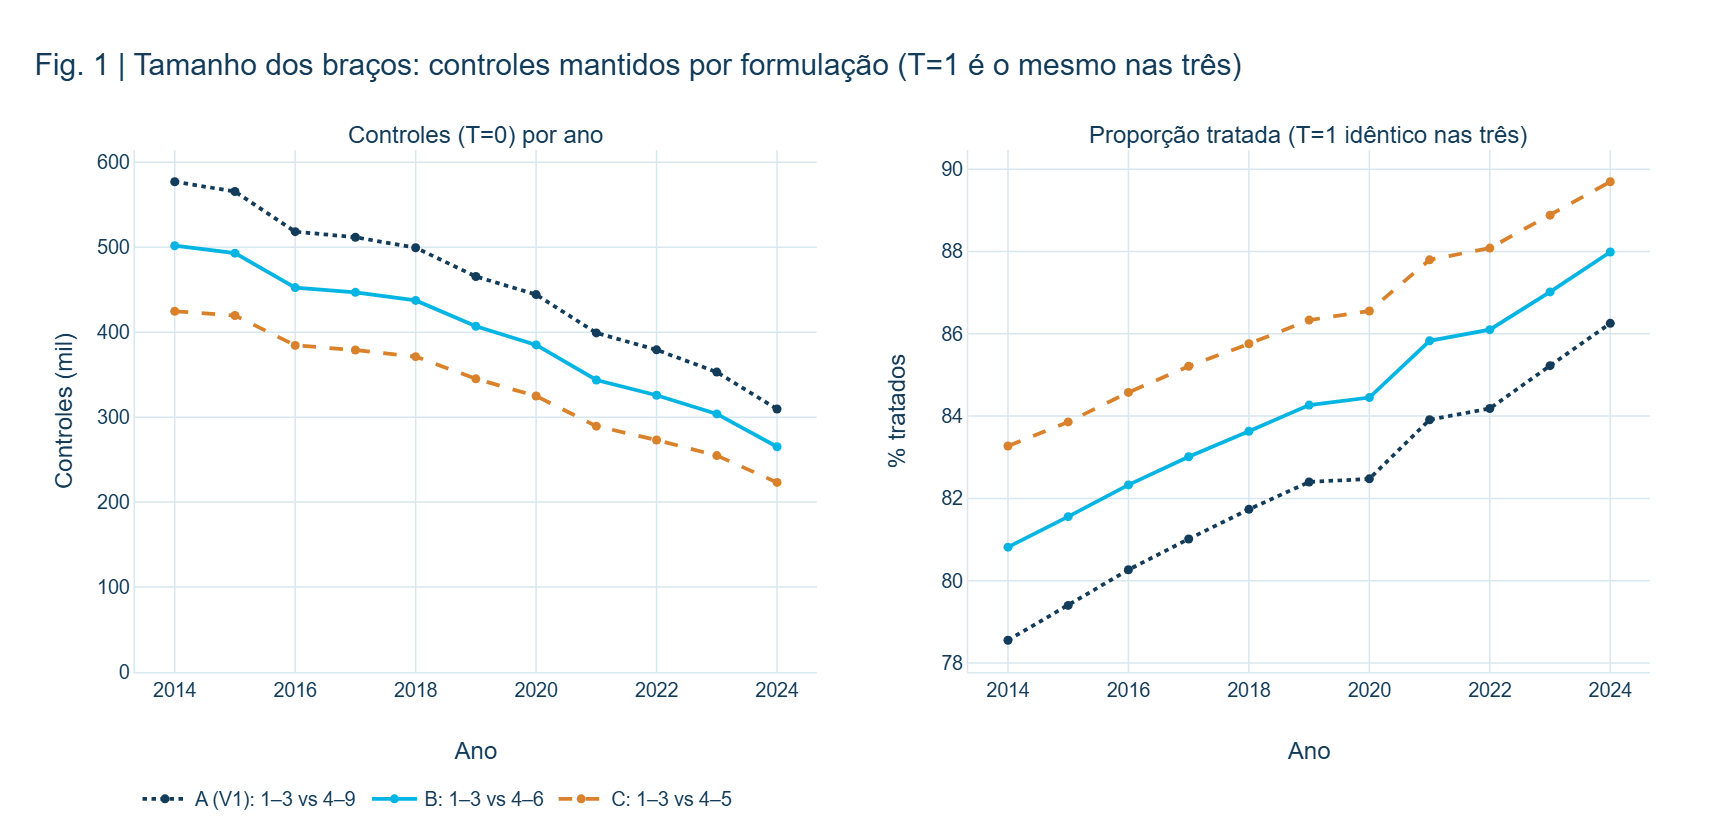

In [14]:
CORES = {'A_V1': CORES_IPT['AZUL_ESCURO'], 'B': CORES_IPT['CIANO'], 'C': '#D9822B'}
TRACO = {'A_V1': 'dot', 'B': 'solid', 'C': 'dash'}
anos_eixo = list(v2.ANOS)

def serie(formulacao, coluna):
    return diagnostico[diagnostico.formulacao == formulacao].set_index('ano')[coluna].reindex(anos_eixo)

# Figura 1 — N por braço
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.1, subplot_titles=('Controles (T=0) por ano', 'Proporção tratada (T=1 idêntico nas três)'))
for f in v2.FORMULACOES_DIAGNOSTICADAS:
    fig.add_scatter(x=anos_eixo, y=serie(f, 'n_t0') / 1000, mode='lines+markers', name=ROTULO[f],
                    line=dict(color=CORES[f], dash=TRACO[f], width=2.5), row=1, col=1, legendgroup=f)
    fig.add_scatter(x=anos_eixo, y=100 * serie(f, 'proporcao_t1'), mode='lines+markers', name=ROTULO[f], showlegend=False,
                    line=dict(color=CORES[f], dash=TRACO[f], width=2.5), row=1, col=2, legendgroup=f)
fig.update_yaxes(title_text='Controles (mil)', rangemode='tozero', row=1, col=1)
fig.update_yaxes(title_text='% tratados', row=1, col=2)
fig.update_xaxes(title_text='Ano', dtick=2)
mostrar(fig, 'Fig. 1 | Tamanho dos braços: controles mantidos por formulação (T=1 é o mesmo nas três)', 'fig1_n_bracos')

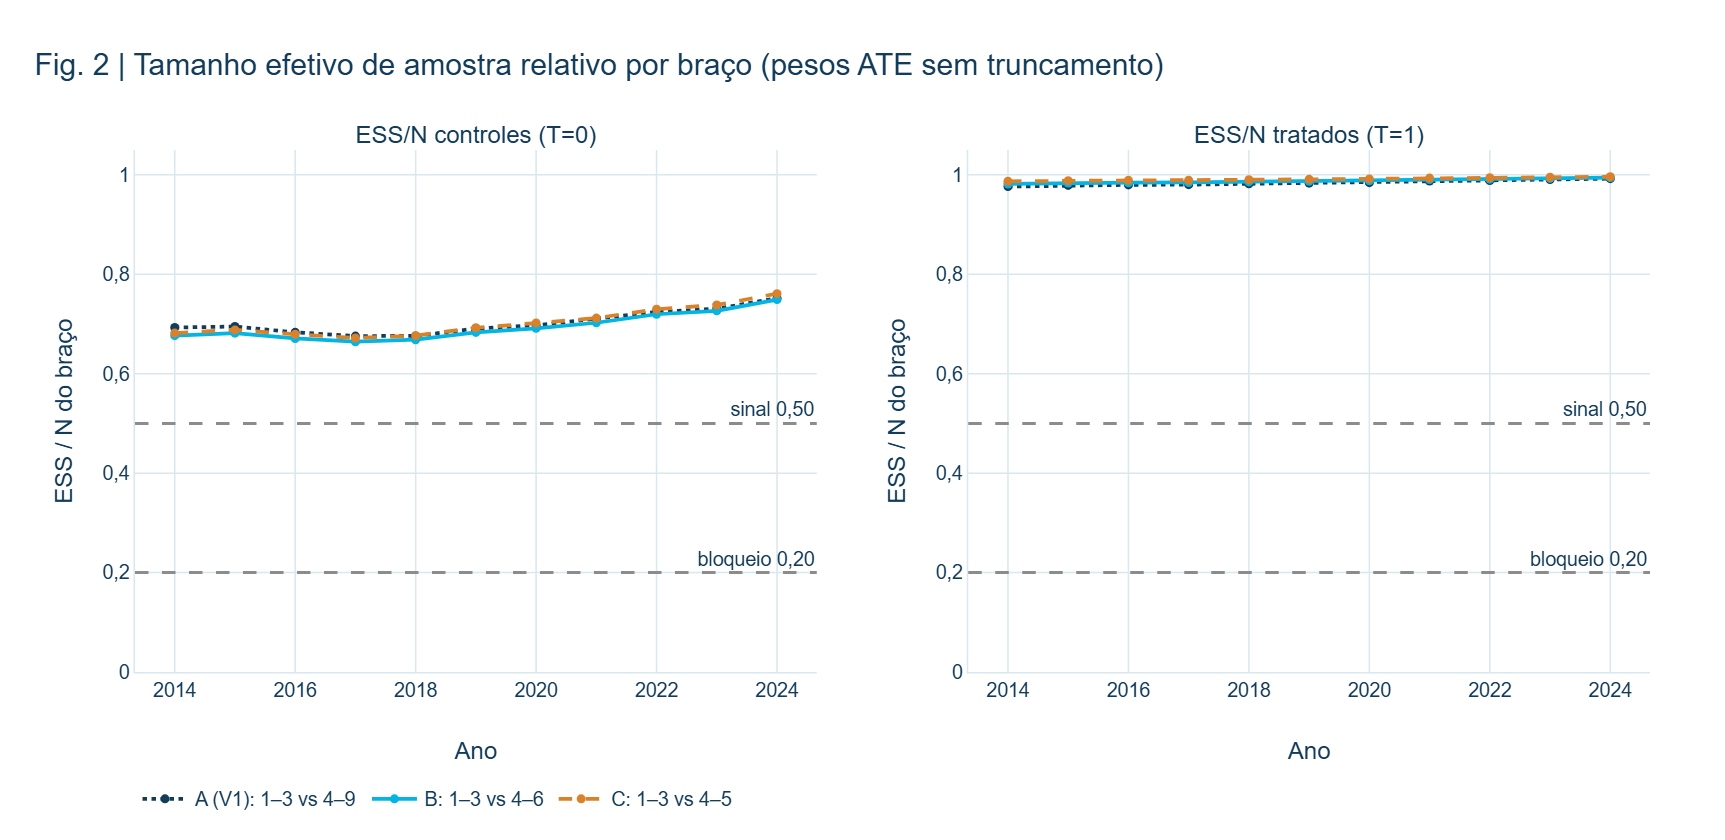

In [15]:
# Figura 2 — ESS relativo
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.1, subplot_titles=('ESS/N controles (T=0)', 'ESS/N tratados (T=1)'))
for col, coluna in ((1, 'ess_t0_sobre_n'), (2, 'ess_t1_sobre_n')):
    for f in v2.FORMULACOES_DIAGNOSTICADAS:
        fig.add_scatter(x=anos_eixo, y=serie(f, coluna), mode='lines+markers', name=ROTULO[f], showlegend=(col == 1),
                        line=dict(color=CORES[f], dash=TRACO[f], width=2.5), row=1, col=col, legendgroup=f)
    for limite, rotulo_lim in ((v2.LIMIARES['ess_relativo_sinal'], 'sinal 0,50'), (v2.LIMIARES['ess_relativo_bloqueio'], 'bloqueio 0,20')):
        fig.add_hline(y=limite, line_dash='dash', line_color='#8C8C8C', annotation_text=rotulo_lim, row=1, col=col)
fig.update_yaxes(title_text='ESS / N do braço', range=[0, 1.05])
fig.update_xaxes(title_text='Ano', dtick=2)
mostrar(fig, 'Fig. 2 | Tamanho efetivo de amostra relativo por braço (pesos ATE sem truncamento)', 'fig2_ess_relativo')

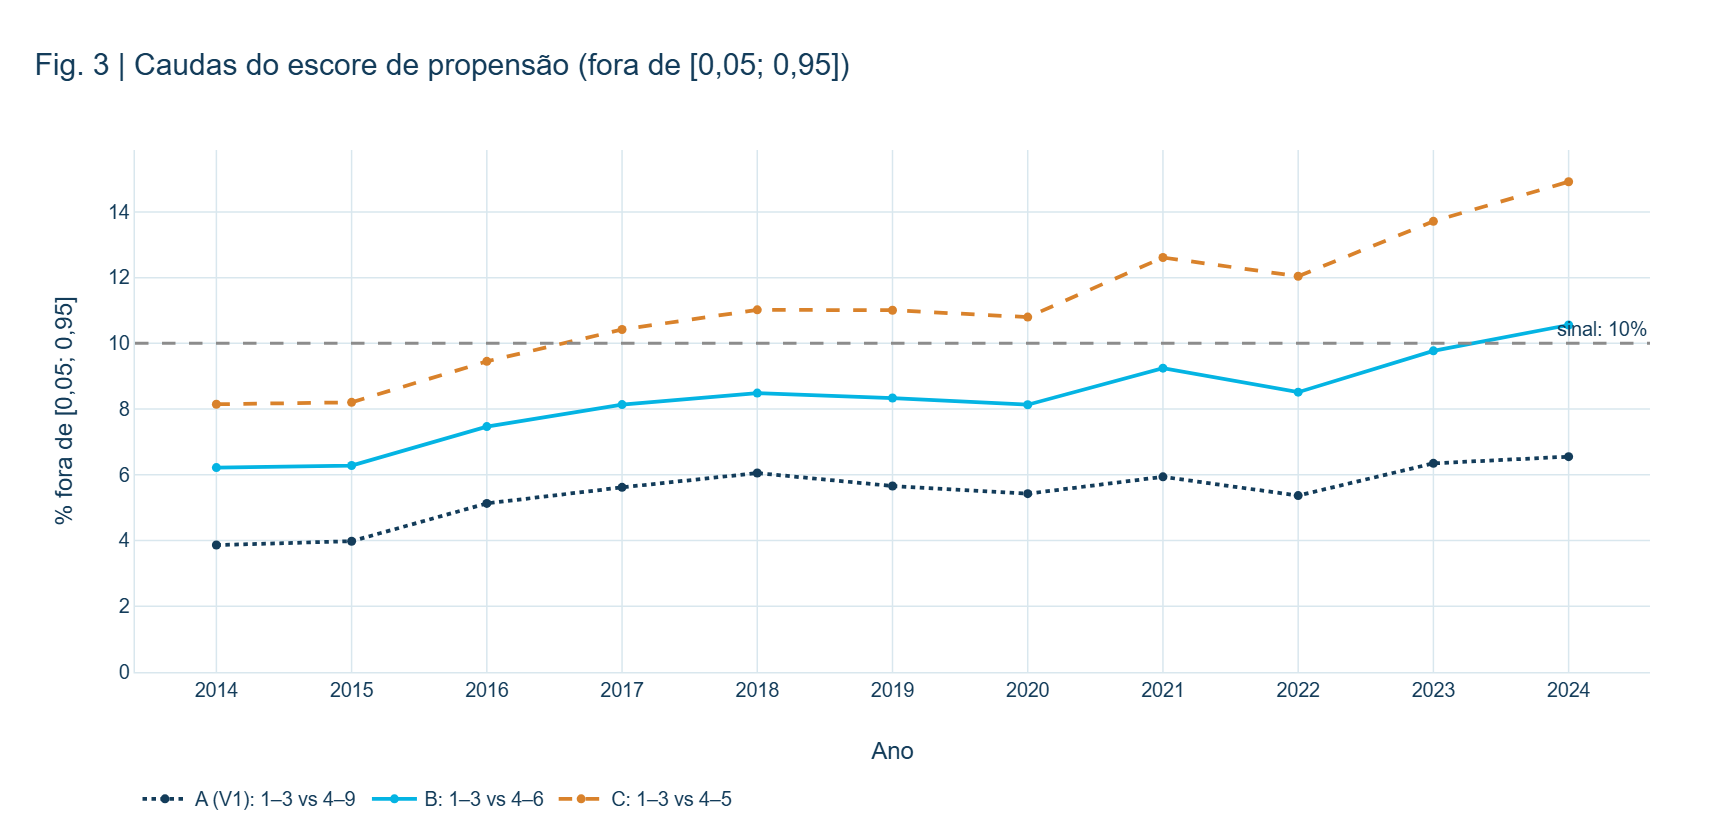

In [16]:
# Figura 3 — caudas fora de [0,05; 0,95]
fig = go.Figure()
for f in v2.FORMULACOES_DIAGNOSTICADAS:
    fig.add_scatter(x=anos_eixo, y=100 * serie(f, 'fora_005_095_fracao'), mode='lines+markers', name=ROTULO[f],
                    line=dict(color=CORES[f], dash=TRACO[f], width=2.5))
fig.add_hline(y=100 * v2.LIMIARES['fora_005_095_max'], line_dash='dash', line_color='#8C8C8C', annotation_text='sinal: 10%')
fig.update_yaxes(title_text='% fora de [0,05; 0,95]', rangemode='tozero')
fig.update_xaxes(title_text='Ano', dtick=1)
mostrar(fig, 'Fig. 3 | Caudas do escore de propensão (fora de [0,05; 0,95])', 'fig3_caudas_005_095')

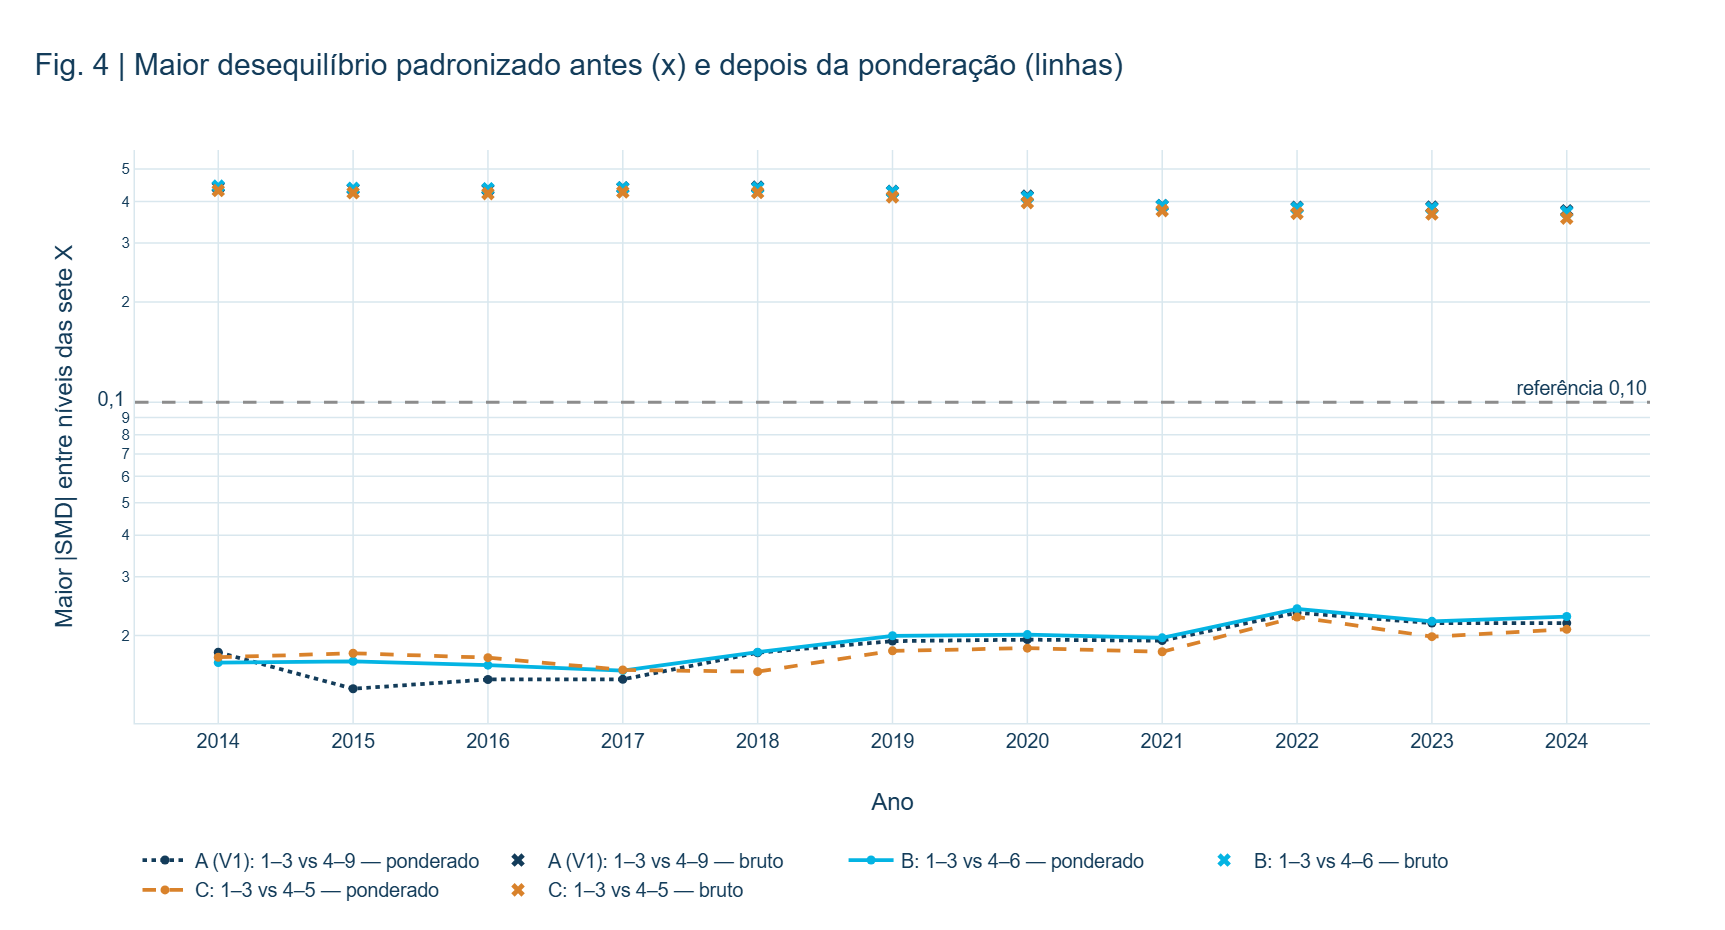

In [17]:
# Figura 4 — maior |SMD|
fig = go.Figure()
for f in v2.FORMULACOES_DIAGNOSTICADAS:
    fig.add_scatter(x=anos_eixo, y=serie(f, 'max_abs_smd_ponderado'), mode='lines+markers', name=f'{ROTULO[f]} — ponderado',
                    line=dict(color=CORES[f], dash=TRACO[f], width=2.5))
    fig.add_scatter(x=anos_eixo, y=serie(f, 'max_abs_smd_bruto'), mode='markers', name=f'{ROTULO[f]} — bruto',
                    marker=dict(color=CORES[f], symbol='x', size=8))
fig.add_hline(y=v2.LIMIARES['smd_ponderado_max'], line_dash='dash', line_color='#8C8C8C')
fig.add_annotation(x=1, xref='paper', xanchor='right', y=np.log10(v2.LIMIARES['smd_ponderado_max']), yanchor='bottom',
                   text='referência 0,10', showarrow=False)
fig.update_yaxes(title_text='Maior |SMD| entre níveis das sete X', type='log')
fig.update_xaxes(title_text='Ano', dtick=1)
mostrar(fig, 'Fig. 4 | Maior desequilíbrio padronizado antes (x) e depois da ponderação (linhas)', 'fig4_smd', altura=620)

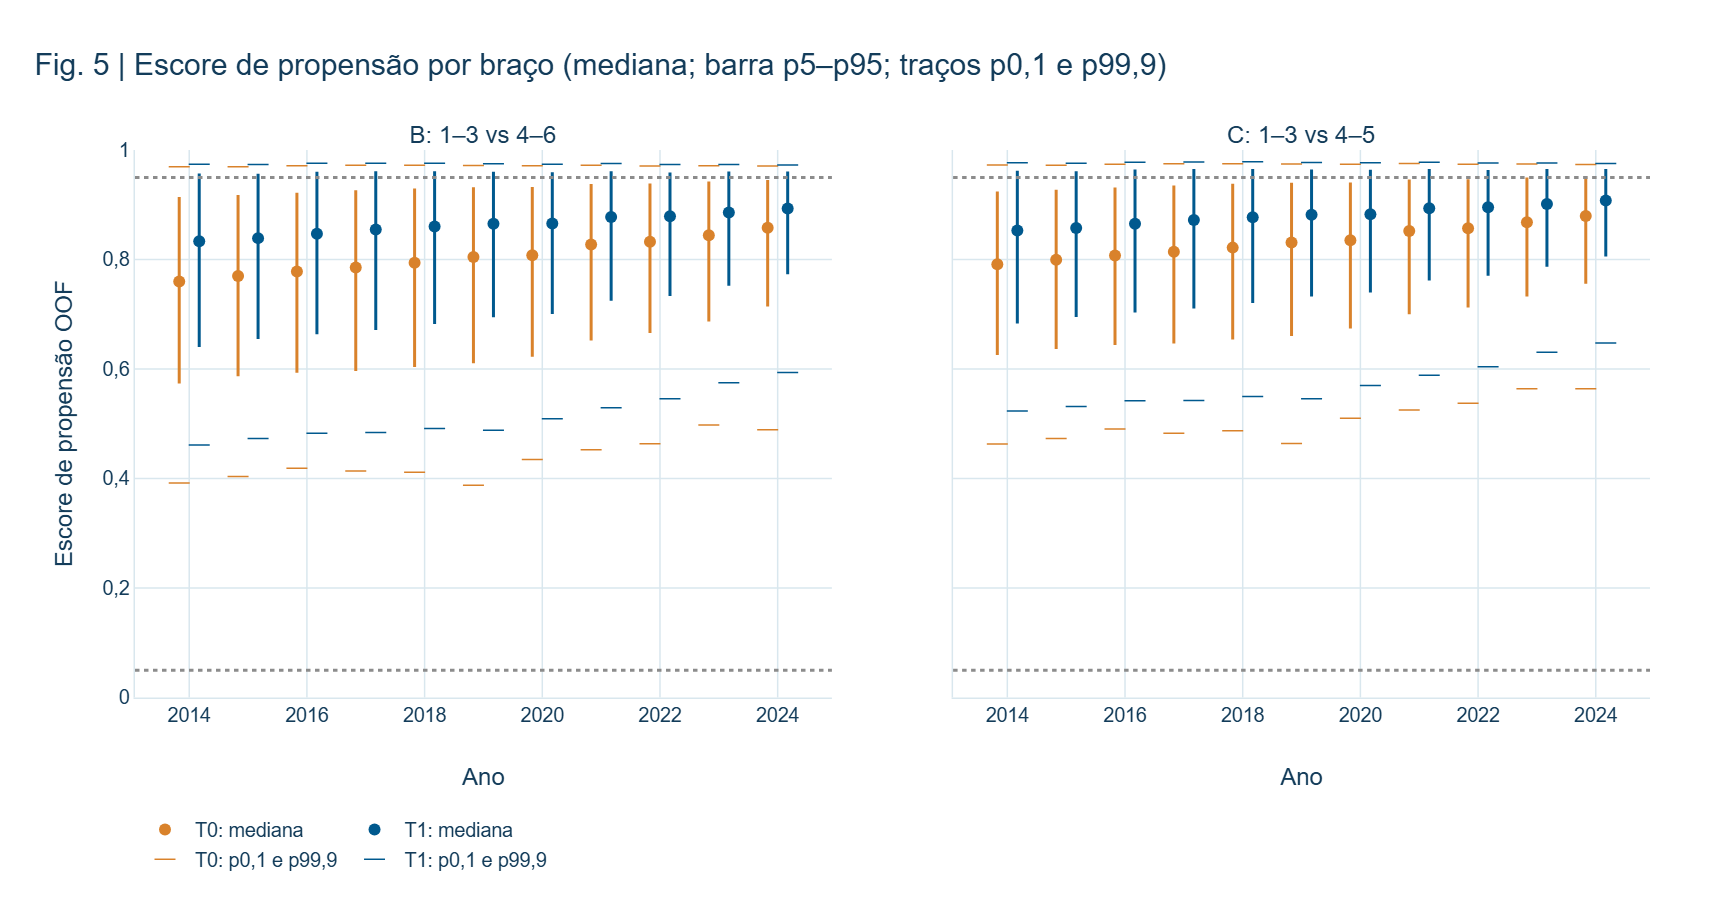

In [18]:
# Figura 5 — distribuição resumida do propensity por braço (B e C)
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.08, shared_yaxes=True,
                    subplot_titles=(ROTULO['B'], ROTULO['C']))
for col, f in ((1, 'B'), (2, 'C')):
    for braco, cor, deslocamento in (('T0', '#D9822B', -0.17), ('T1', CORES_IPT['AZUL_PRINCIPAL'], 0.17)):
        q = quantis_bracos[(quantis_bracos.formulacao == f) & (quantis_bracos.braco == braco)].set_index('ano').reindex(anos_eixo)
        x = [a + deslocamento for a in anos_eixo]
        fig.add_scatter(x=x, y=q['p50'], mode='markers', name=f'{braco}: mediana', showlegend=(col == 1), legendgroup=braco,
                        marker=dict(color=cor, size=8),
                        error_y=dict(type='data', symmetric=False, array=q['p95'] - q['p50'], arrayminus=q['p50'] - q['p5'],
                                     color=cor, thickness=2, width=0), row=1, col=col)
        fig.add_scatter(x=x, y=q['p0.1'], mode='markers', name=f'{braco}: p0,1 e p99,9', showlegend=(col == 1), legendgroup=braco,
                        marker=dict(color=cor, symbol='line-ew-open', size=10), row=1, col=col)
        fig.add_scatter(x=x, y=q['p99.9'], mode='markers', showlegend=False, legendgroup=braco,
                        marker=dict(color=cor, symbol='line-ew-open', size=10), row=1, col=col)
for col in (1, 2):
    for limite in (0.05, 0.95):
        fig.add_hline(y=limite, line_dash='dot', line_color='#8C8C8C', row=1, col=col)
fig.update_yaxes(title_text='Escore de propensão OOF', range=[0, 1], row=1, col=1)
fig.update_xaxes(title_text='Ano', dtick=2)
mostrar(fig, 'Fig. 5 | Escore de propensão por braço (mediana; barra p5–p95; traços p0,1 e p99,9)', 'fig5_distribuicao_propensity', altura=600)

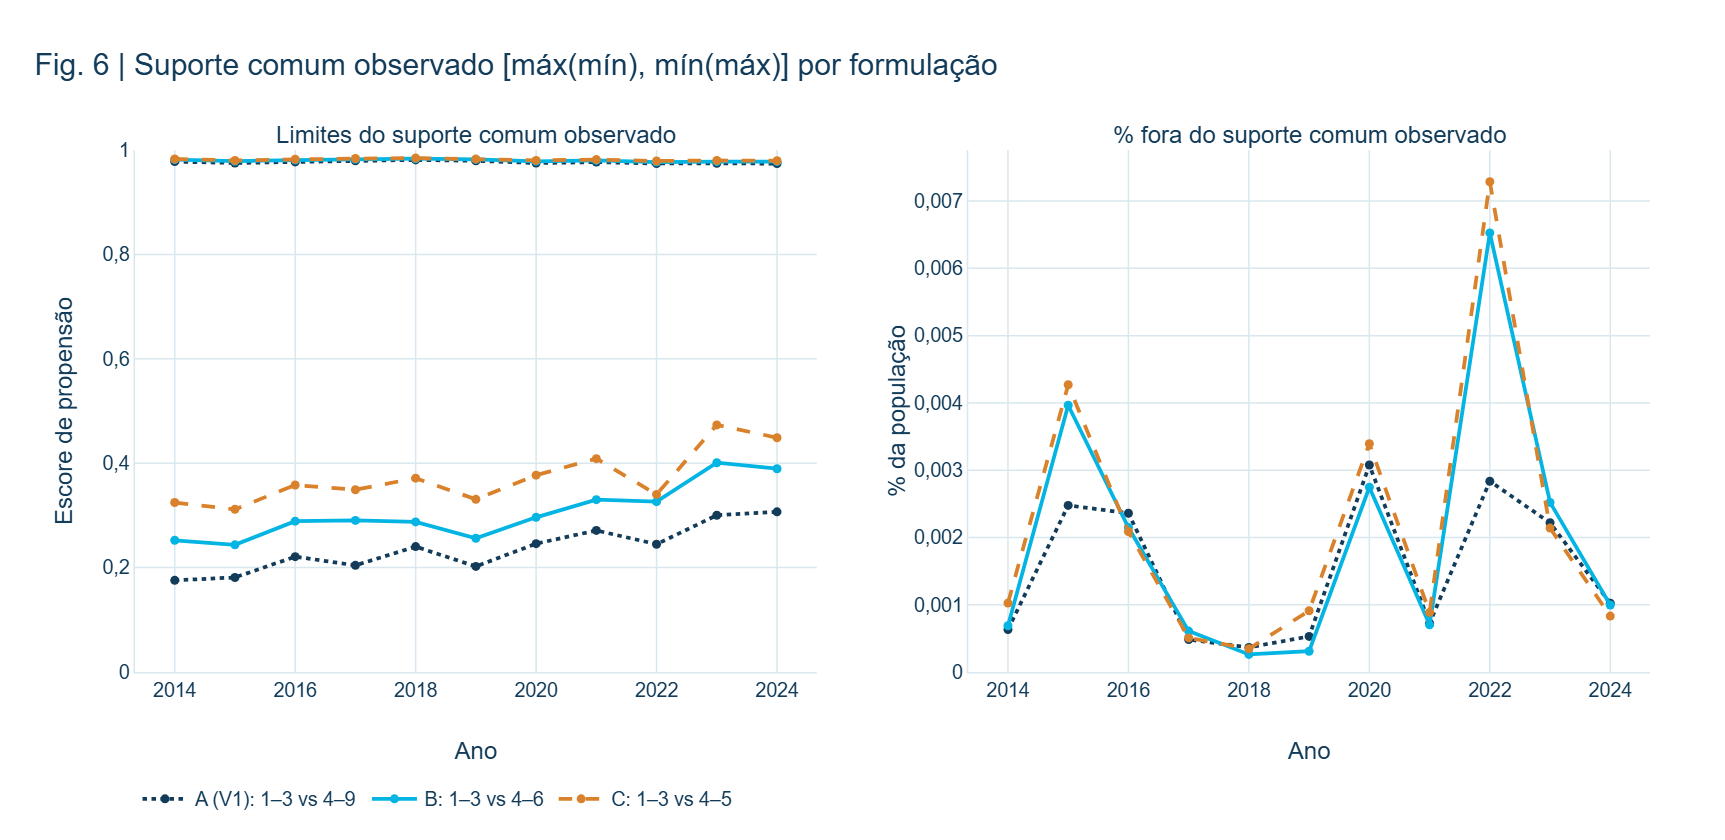

In [19]:
# Figura 6 — suporte comum observado
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.1,
                    subplot_titles=('Limites do suporte comum observado', '% fora do suporte comum observado'))
for f in v2.FORMULACOES_DIAGNOSTICADAS:
    for coluna, mostrar_leg in (('suporte_comum_inferior', True), ('suporte_comum_superior', False)):
        fig.add_scatter(x=anos_eixo, y=serie(f, coluna), mode='lines+markers', name=ROTULO[f], showlegend=mostrar_leg,
                        line=dict(color=CORES[f], dash=TRACO[f], width=2.5), row=1, col=1, legendgroup=f)
    fig.add_scatter(x=anos_eixo, y=100 * serie(f, 'fora_suporte_comum_fracao'), mode='lines+markers', showlegend=False,
                    line=dict(color=CORES[f], dash=TRACO[f], width=2.5), row=1, col=2, legendgroup=f)
fig.update_yaxes(title_text='Propensity', range=[0, 1], row=1, col=1)
fig.update_yaxes(title_text='% da população', rangemode='tozero', row=1, col=2)
fig.update_xaxes(title_text='Ano', dtick=2)
mostrar(fig, 'Fig. 6 | Suporte comum observado [máx(mín), mín(máx)] por formulação', 'fig6_suporte_comum')

**Leitura do diagnóstico (sem efeito).**

- **Reconciliação.** Em todos os 33 pares formulação × ano, T1 coincide com o notebook 08 e T0 com o D7 do 09c; o hash de cada Parquet confere com o manifesto; a chave é única; não há datas inválidas. Cada população tem 5.580–5.587 municípios de residência, o que atende à inferência agrupada futura.
- **Atribuição.** AUC OOF 0,661–0,690 em B e 0,655–0,684 em C, contra 0,663–0,691 em A: as sete X separam os braços de forma moderada e quase igual nas três formulações. A calibração por decis é próxima da diagonal (erro máximo ≤ 0,0055 em B e ≤ 0,0039 em C). Essas métricas são preditivas e não são critério causal.
- **Balanceamento.** O maior |SMD| bruto (situação conjugal, 0,36–0,44) cai, após a ponderação, para 0,016–0,024 em B e 0,016–0,023 em C. O nível mais difícil é a idade materna média. Nenhum ano se aproxima de 0,10.
- **ESS.** O ESS relativo dos controles fica entre 0,66 e 0,76 nas três formulações e é praticamente igual entre A, B e C em cada ano (diferença máxima de 0,016). Restringir o comparador não degrada a eficiência relativa. O ESS absoluto cai com o N (B 2024: ≈198,7 mil controles efetivos; C 2024: ≈169,8 mil).
- **Suporte.** Nenhum escore fica fora de [0,01; 0,99]. O mínimo do escore sobe de A para C (2024: 0,31 → 0,39 → 0,45), e menos de 0,01% da população fica fora do suporte comum observado em qualquer ano.
- **Caudas e pesos.** Toda a fração fora de [0,05; 0,95] está acima de 0,95 e é dominada por tratados (B 2024: 223.246 tratados e 9.818 controles). A sinalização de B 2024 e de C 2017–2024 vem dessa cauda superior, que cresce com a proporção tratada, e não de perda de balanceamento ou de ESS. O risco relevante para o AIPW futuro está nos controles com escore alto: peso máximo de 43–60 (p99,9 de 32–36) em B e de 47–65 (p99,9 de 36–40) em C, contra 38–53 em A.
- **Resposta à pergunta da rodada.** B e C **permanecem estatisticamente viáveis** depois da mudança de comparador: nenhum ano é bloqueado, e o balanceamento e o ESS ficam no nível da V1. O custo de suporte é uma cauda superior maior, já prevista pelo trimming de sensibilidade [0,05; 0,95] (pré-especificado, que muda o estimando). Essa cauda supera o limiar convencional em 1 de 11 anos em B e em 8 de 11 em C. Os anos sinalizados permanecem na análise.

## 30. Desempenho: tempo, memória e disco

In [20]:
tempo_total = time.perf_counter() - INICIO_NOTEBOOK
print(f'Tempo total do notebook: {tempo_total / 60:.1f} min | diagnóstico A/B/C: {tempo_diagnostico / 60:.1f} min')
display(execucao.groupby('formulacao')[['segundos_carga', 'segundos_ajuste', 'segundos_diagnostico', 'segundos_total']].sum().div(60).round(2)
        .rename(columns=lambda c: c.replace('segundos', 'minutos')))
display(execucao.groupby('formulacao')[['rss_mb', 'pico_mb']].max().round(0))
ajustados = folds[folds.origem == 'ajuste'] if 'origem' in folds else folds.iloc[0:0]
if len(ajustados):
    display(ajustados.groupby('formulacao')[['segundos', 'n_iter']].agg(['count', 'mean', 'max']).round(1))
print('Partições reutilizadas de checkpoint:', int((folds.get('origem') == 'cache').sum()) if 'origem' in folds else 0)
def tamanho(pasta_alvo):
    arquivos = [p for p in pasta_alvo.rglob('*') if p.is_file()]
    return len(arquivos), sum(p.stat().st_size for p in arquivos)
n_cache, bytes_cache = tamanho(pasta_cache)
n_saidas, bytes_saidas = tamanho(pasta)
print(f'Checkpoints: {n_cache} arquivos, {bytes_cache / 2**20:,.1f} MiB em data/interim/v2_pre_estimacao/')
print(f'Saídas: {n_saidas} arquivos, {bytes_saidas / 2**20:,.2f} MiB em outputs/temporal/v2_pre_estimacao/')

Tempo total do notebook: 29.3 min | diagnóstico A/B/C: 27.4 min


,minutos_carga,minutos_ajuste,minutos_diagnostico,minutos_total
formulacao,,,,
A_V1,4.0700,0.0000,3.2900,9.8400
B,3.8800,0.0600,3.1200,9.3200
C,3.3000,0.0500,2.6900,7.9800


,rss_mb,pico_mb
formulacao,,
A_V1,"1,538.0000","2,513.0000"
B,"1,682.0000","2,544.0000"
C,"1,756.0000","2,544.0000"


Partições reutilizadas de checkpoint: 120
Checkpoints: 240 arquivos, 195.4 MiB em data/interim/v2_pre_estimacao/
Saídas: 23 arquivos, 1.63 MiB em outputs/temporal/v2_pre_estimacao/


## 31. Artefatos, manifesto e preservação

In [21]:
salvar_tabela(diagnostico, 'diagnostico_suporte_v2', 'Propensity, suporte, caudas, ESS, SMD, pesos e gate por formulação e ano (sem efeito)',
              'formulação x ano', 'formulacao, ano', 'N reconciliado com 08/09c; gates aplicados mecanicamente',
              'diagnóstico de viabilidade; não avalia confundimento não medido', 'revisão humana antes do AIPW V2')
salvar_tabela(balanco, 'balanceamento_v2', 'SMD bruto e ponderado por nível das sete X', 'formulação x ano x variável x nível',
              'formulacao, ano, variavel, nivel', 'mesma definição de src.selecao_nuisance (testada)',
              'pesos ATE sem truncamento', 'revisão humana')
salvar_tabela(quantis_bracos, 'quantis_propensity_bracos_v2', 'Quantis do propensity por braço', 'formulação x ano x braço',
              'formulacao, ano, braco', 'OOF com cobertura exata', 'resumo; sem registros individuais', 'revisão humana')
salvar_tabela(composicao, 'composicao_mesprenat_v2', 'N por mês de início em cada população', 'formulação x ano x mês',
              'formulacao, ano, mesprenat', 'soma = N da população', 'descritivo', 'revisão humana')
salvar_tabela(execucao, 'execucao_v2', 'Tempo e memória por formulação e ano', 'formulação x ano', 'formulacao, ano',
              'medido nesta execução', 'tempos de reexecução refletem checkpoints', 'planejar orçamento do AIPW V2')
salvar_tabela(folds, 'particoes_v2', 'Log das partições (iterações, tempo, origem)', 'formulação x ano x partição',
              'formulacao, ano, fold', 'todos os ajustes convergiram', 'A usa cache do 08 (sem log por partição)', 'revisão humana')
salvar_tabela(controle_positivo, 'controle_positivo_v1_a', 'A reajustada pelo código novo versus OOF certificado do 08',
              'ano', 'ano', 'diferença máxima <= 1e-12', 'dois anos (um por regra de ordem)', 'repetir no AIPW V2 para a V1')
resultado_gates = {
    'hash_contrato': contrato_registrado['hash_contrato'],
    'hash_criterios': hash_criterios,
    'avaliado_em': datetime.now().isoformat(timespec='seconds'),
    'por_ano': diagnostico[['formulacao', 'ano', 'status', 'motivo', 'bloqueios', 'sinais']].to_dict('records'),
    **consolidado,
    'NENHUM_EFEITO_V2_ESTIMADO': True, 'V1_PRESERVADA': True, 'SEM_RESULT_SHOPPING': True,
}
salvar_json(resultado_gates, 'gates_suporte_v2.json', 'Status por formulação/ano e veredictos de suporte',
            'critérios com hash registrado no contrato antes do primeiro ajuste', 'viabilidade estatística, não identificação',
            'revisão humana')

In [22]:
protegidos_fim = impressoes_protegidas()
alterados = sorted(k for k in protegidos_inicio if protegidos_fim.get(k) != protegidos_inicio[k])
novos_protegidos = sorted(set(protegidos_fim) - set(protegidos_inicio))
print('Arquivos protegidos alterados:', alterados)
print('Arquivos novos fora das pastas desta rodada:', novos_protegidos)
assert not alterados and not novos_protegidos, 'Arquivo protegido alterado/criado'
git_status_fim = git('status', '--short', '--untracked-files=all')
novos_git = sorted(set(git_status_fim.splitlines()) - set(git_status_inicio.splitlines()))
print('Entradas novas no git status:')
print('\n'.join(novos_git))
manifesto = {
    'notebook': 'notebooks/09d_contrato_v2_pre_estimacao.ipynb',
    'executado_em': datetime.now().isoformat(timespec='seconds'),
    'branch': git_branch, 'head': git_head,
    'hash_contrato': contrato_registrado['hash_contrato'], 'contrato_registrado_em': contrato_registrado['registrado_em'],
    'codigo_sha256': v2.sha256_codigo(raiz), 'versoes': v2.versoes_bibliotecas(),
    'tempo_total_minutos': (time.perf_counter() - INICIO_NOTEBOOK) / 60,
    'tempo_diagnostico_minutos': tempo_diagnostico / 60,
    'rss_max_mb': float(execucao.rss_mb.max()), 'pico_processo_mb': float(execucao.pico_mb.max()),
    'checkpoints': {'pasta': 'data/interim/v2_pre_estimacao', 'arquivos': n_cache, 'bytes': bytes_cache},
    'protegidos_monitorados': len(protegidos_inicio), 'protegidos_alterados': alterados,
    'saidas': saidas,
    'veredictos': {'decisao': 'DECISAO_V2_PRE_ESTIMACAO_CONGELADA', 'B': 'V2_PRINCIPAL_B_1A3_VS_4A6',
                   'C': 'SENSIBILIDADE_V2_C_1A3_VS_4A5', 'A': 'V1_A_PRESERVADA_COMO_HISTORICA', 'D': 'LANDMARK_D_PENDENTE',
                   'suporte': consolidado['SUPORTE_V2'], 'suporte_C': consolidado['SUPORTE_SENSIBILIDADE_C'],
                   'NENHUM_EFEITO_V2_ESTIMADO': True, 'V1_PRESERVADA': True, 'SEM_RESULT_SHOPPING': True,
                   'prontidao': consolidado['PRONTIDAO']},
}
salvar_json(manifesto, 'manifesto_v2_pre_estimacao.json', 'Manifesto da execução do 09d', 'hashes e preservação conferidos',
            'congelamento sem commit', 'revisão humana')
print(json.dumps(manifesto['veredictos'], ensure_ascii=False, indent=1))

Arquivos protegidos alterados: []
Arquivos novos fora das pastas desta rodada: []
Entradas novas no git status:
?? docs/temporal/CONTRATO_V2_PRE_ESTIMACAO.md
{
 "decisao": "DECISAO_V2_PRE_ESTIMACAO_CONGELADA",
 "B": "V2_PRINCIPAL_B_1A3_VS_4A6",
 "C": "SENSIBILIDADE_V2_C_1A3_VS_4A5",
 "A": "V1_A_PRESERVADA_COMO_HISTORICA",
 "D": "LANDMARK_D_PENDENTE",
 "suporte": "SUPORTE_V2_SINALIZADO",
 "suporte_C": "SUPORTE_SENSIBILIDADE_C_SINALIZADO",
 "NENHUM_EFEITO_V2_ESTIMADO": true,
 "V1_PRESERVADA": true,
 "SEM_RESULT_SHOPPING": true,
 "prontidao": "PRONTO_PARA_REVISAO_HUMANA_ANTES_DOS_EFEITOS"
}


## 32. Vereditos

| Veredito | Estado |
| --- | --- |
| Decisão | **`DECISAO_V2_PRE_ESTIMACAO_CONGELADA`** |
| V2 principal | `V2_PRINCIPAL_B_1A3_VS_4A6` |
| Sensibilidade | `SENSIBILIDADE_V2_C_1A3_VS_4A5` |
| V1 | `V1_A_PRESERVADA_COMO_HISTORICA` |
| D | `LANDMARK_D_PENDENTE` |
| Suporte V2 (B) | **`SUPORTE_V2_SINALIZADO`** — 10 anos `APROVADO`; 2024 `SINALIZADO` (caudas fora de [0,05; 0,95] = 10,56%); nenhum ano `BLOQUEADO` |
| Suporte da sensibilidade C | `SUPORTE_SENSIBILIDADE_C_SINALIZADO` — 2017–2024 `SINALIZADO` (caudas de 10,4% a 14,9%); nenhum ano `BLOQUEADO` |
| Efeitos | `NENHUM_EFEITO_V2_ESTIMADO` |
| V1 | `V1_PRESERVADA` (1.106 arquivos protegidos com impressões idênticas antes e depois) |
| Disciplina | `SEM_RESULT_SHOPPING` |
| Prontidão | **`PRONTO_PARA_REVISAO_HUMANA_ANTES_DOS_EFEITOS`** |

Nada foi commitado. O congelamento é documental e de artefatos; a revisão humana decide sobre o commit e sobre a passagem à estimação.

## 33. Limitações e próximos passos

**Limitações.**

- B **não** resolve o *immortal time bias*. Ela reduz substancialmente o componente empiricamente identificado de incompatibilidade temporal, mas permanecem a classificação retrospectiva do mês de início, o uso de informação futura na definição da população (excluir 7–9), o confundimento residual, a seleção por nascido vivo, o missing diferencial de `MESPRENAT` e o erro de mensuração não validado.
- A, B e C são estimandos diferentes; suas estimativas futuras não podem ser lidas como versões "corrigidas" umas das outras.
- Os gates medem viabilidade de atribuição e suporte sob o modelo logístico histórico com 5 partições. O AIPW futuro usará 3 partições estratificadas por `2T+Y`, com escores reajustados, de modo que extremos e pesos podem diferir um pouco dos aqui reportados.
- O limiar de 10% para as caudas é uma convenção do projeto. A sinalização reflete sobretudo a cauda superior dos tratados, cuja proporção cresce com a restrição do comparador.
- A janela de sensibilidade 2018–2024 tem o mesmo status de B e de C que a janela principal nos anos comuns, pois os anos não se misturam.
- `MESPRENAT=99` permanece `CODIFICACAO_OPERACIONAL_OBSERVADA`. Os documentos históricos que o tratam como definição oficial estão listados na seção 20 e não foram editados.
- A literatura sobre *immortal time*, *target trial* e *landmark* disponível localmente se limita a Hernán & Robins (*What If*). Os textos de Schnitzer, Tyson e Hutcheon & Savitz não foram localizados e não foram citados.

**Próximos passos (só após revisão humana).**

1. Revisar e decidir o commit deste contrato, do módulo, dos testes, do notebook e dos artefatos.
2. Retomar a frente 09b, pausada e preservada.
3. Implementar o AIPW V2 com controle positivo da V1 (A) em 2024 e, em seguida, estimar B e C ano a ano com C1/C2/C3 reajustados, mantendo o trimming de sensibilidade [0,05; 0,95] como pré-especificado e reportando B 2024 e C 2017–2024 com a sinalização.
4. Seguir o roadmap da seção 17: sem perdas fetais, E-value, subgrupos, COVID-19, quebras temporais, *landmark* D, PIG, CATE e novos meta-learners, cada um com pré-especificação própria.